# **ADVANCED MODELLING NOTEBOOK**

1. Notebook Setup and Objectives
2. Load Prepared Modelling Data
3. Experimental Design and Evaluation Strategy
4. Advanced Model Candidates
5. Imbalance-Aware Modelling
6. Hyperparameter Optimisation
7. Tuned Model Evaluation
8. Advanced Model Comparison
9. Comparison Against Python Baseline and AI Studio
10. Candidate Final Model Selection
11. Save Models and Results
12. Section Conclusions

In [2]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

## 1. Notebook Setup and Objectives

1.1 Notebook Purpose

This notebook develops the advanced modelling stage of the credit-risk project.

The previous baseline modelling stage established two important performance references:

- **AI Studio benchmark:** ROC-AUC = **0.724**
- **Best Python baseline:** Gradient Boosting, ROC-AUC = **0.7578**

The purpose of the current notebook is therefore not simply to train additional models.

Instead, the objective is to determine whether more sophisticated modelling strategies, controlled hyperparameter optimisation and imbalance-aware learning can improve upon the strongest Python baseline while maintaining a rigorous and reproducible experimental design.

The primary technical objective is:

> Achieve a validation ROC-AUC greater than the current Python baseline of **0.7578** without introducing data leakage.

Supporting metrics such as PR-AUC, Precision, Recall and F1-score are also monitored because the target variable is strongly imbalanced.

1.2 Experimental Principles

The advanced modelling workflow follows several strict experimental principles.

1. **Training data is used for model fitting and hyperparameter optimisation.**

2. **Validation data is used for model comparison and candidate-model selection.**

3. **The internal test set remains untouched during advanced model development.**

4. **ROC-AUC remains the primary model-selection metric.**

5. **PR-AUC is retained as an important complementary metric because the positive class is relatively rare.**

6. **Threshold-dependent metrics such as Precision, Recall and F1-score are monitored, but threshold optimisation is deferred to the Evaluation notebook.**

7. **No preprocessing transformation is refitted using validation or test data.**

8. **Random seeds are fixed wherever stochastic behaviour is present to support reproducibility.**

9. **Hyperparameter optimisation is performed only on the training partition.**

10. **Advanced models are compared against both the AI Studio benchmark and the strongest Python baseline.**

1.3 Performance References

In [112]:
AI_STUDIO_BENCHMARK_MODEL = "Gradient Boosted Trees"
AI_STUDIO_BENCHMARK_VALIDATION_AUC = 0.724

PYTHON_BASELINE_MODEL = "Gradient Boosting"
PYTHON_BASELINE_VALIDATION_AUC = 0.7578

In [113]:
benchmark_reference = pd.DataFrame({
    "Reference": ["AI Studio Benchmark", "Python Baseline"],
    "Model": [AI_STUDIO_BENCHMARK_MODEL, PYTHON_BASELINE_MODEL],
    "Validation ROC-AUC": [AI_STUDIO_BENCHMARK_VALIDATION_AUC, PYTHON_BASELINE_VALIDATION_AUC]
})
benchmark_reference

,Reference,Model,Validation ROC-AUC
0,AI Studio Benchmark,Gradient Boosted Trees,0.7240
1,Python Baseline,Gradient Boosting,0.7578


The AI Studio result remains the formal external benchmark required by the project.

However, the stronger Python Gradient Boosting result of **0.7578** now represents the principal technical baseline that advanced modelling must attempt to improve.

1.4 Random Seed

A fixed random seed of `1992` is used throughout the advanced modelling workflow wherever supported by the modelling algorithm or optimisation procedure.

This is consistent with the reproducibility controls used during the previous modelling stages.

In [114]:
RANDOM_STATE = 1992

1.5 Project Paths

In [115]:
PROJECT_ROOT = Path("..")
DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
OUTPUT_DIR = (PROJECT_ROOT / "outputs" / "advanced_modelling")
MODEL_DIR = (PROJECT_ROOT / "models" / "advanced")
BASELINE_DATA_DIR = (PROCESSED_DATA_DIR / "baseline")
PREPROCESSING_DIR = (PROJECT_ROOT / "models" / "preprocessing")
RESULTS_DIR = OUTPUT_DIR / "results"
FIGURES_DIR = OUTPUT_DIR / "figures"
TUNING_DIR = OUTPUT_DIR / "tuning"

1.6 Create Output Directories

In [116]:
for directory in [
    OUTPUT_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    TUNING_DIR,
    MODEL_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

In [117]:
project_directories = pd.DataFrame({
    "Directory": [
        "Advanced Modelling Output",
        "Results",
        "Figures",
        "Tuning",
        "Advanced Models",
        "Baseline Data",
        "Preprocessing"
    ],
    "Path": [
        OUTPUT_DIR,
        RESULTS_DIR,
        FIGURES_DIR,
        TUNING_DIR,
        MODEL_DIR,
        BASELINE_DATA_DIR,
        PREPROCESSING_DIR
    ],
    "Exists": [
        OUTPUT_DIR.exists(),
        RESULTS_DIR.exists(),
        FIGURES_DIR.exists(),
        TUNING_DIR.exists(),
        MODEL_DIR.exists(),
        BASELINE_DATA_DIR.exists(),
        PREPROCESSING_DIR.exists()
    ]
})

project_directories

,Directory,Path,Exists
0,Advanced Modelling Output,../outputs/advanced_modelling,True
1,Results,../outputs/advanced_modelling/results,True
2,Figures,../outputs/advanced_modelling/figures,True
3,Tuning,../outputs/advanced_modelling/tuning,True
4,Advanced Models,../models/advanced,True
5,Baseline Data,../data/processed/baseline,True
6,Preprocessing,../models/preprocessing,True


1.7 Modelling Constants

In [118]:
TARGET_COLUMN = "TARGET"
ID_COLUMN = "SK_ID_CURR"
PRIMARY_METRIC = "ROC-AUC"
SECONDARY_METRICS = ["PR-AUC", "Accuracy", "Precision", "Recall", "F1"]
DEFAULT_THRESHOLD = 0.50
TARGET_TO_BEAT = PYTHON_BASELINE_VALIDATION_AUC

In [119]:
print("Primary metric:", PRIMARY_METRIC)
print("AI Studio benchmark:", AI_STUDIO_BENCHMARK_VALIDATION_AUC)
print("Python baseline to beat:", TARGET_TO_BEAT)
print("Random state:", RANDOM_STATE)

Primary metric: ROC-AUC
AI Studio benchmark: 0.724
Python baseline to beat: 0.7578
Random state: 1992


1.8 Advanced Modelling Strategy

The advanced modelling workflow will proceed incrementally.

First, the prepared modelling datasets will be loaded and verified to ensure consistency with the previous notebook.

Next, several advanced candidate strategies will be evaluated. These will include stronger ensemble methods and imbalance-aware configurations where appropriate.

Hyperparameter optimisation will then be performed using stratified cross-validation on the training partition only.

The strongest tuned candidates will subsequently be evaluated on the fixed validation set.

Model performance will be compared against:

1. the AI Studio benchmark ROC-AUC of **0.724**, and
2. the Python baseline ROC-AUC of **0.7578**.

The final candidate model will be selected using validation performance together with supporting evidence from PR-AUC and threshold-dependent metrics.

The internal test partition will remain untouched until the final Evaluation stage.

## 2. Load Prepared Modelling Data

In [120]:
ADVANCED_DATA_DIR = (PROCESSED_DATA_DIR / "advanced")
SPLITS_DIR = (PROCESSED_DATA_DIR / "splits")

BASELINE_OUTPUT_DIR = (PROJECT_ROOT / "outputs" / "baseline_models")
BASELINE_PYTHON_RESULTS_DIR = (BASELINE_OUTPUT_DIR / "python")
BASELINE_MODEL_DIR = (PROJECT_ROOT / "models" / "baseline")

The advanced modelling notebook consumes the artefacts generated during Data Preparation.

Two modelling representations are available:

- `advanced_scaled`: intended for algorithms sensitive to feature magnitude.
- `advanced_unscaled`: intended primarily for tree-based algorithms.

The target partitions are loaded from the fixed train/validation split created during Data Preparation.

The internal test artefacts remain stored on disk but are deliberately not loaded during advanced model development.

In [121]:
def find_saved_matrix(directory, base_filename):
    npz_path = (directory / f"{base_filename}.npz")
    npy_path = (directory / f"{base_filename}.npy")

    if npz_path.exists():
        return npz_path

    if npy_path.exists():
        return npy_path
    return None

In [122]:
required_advanced_artifacts = {
    "y_train": SPLITS_DIR / "y_train.csv",
    "y_validation": SPLITS_DIR / "y_validation.csv",
    "y_test": SPLITS_DIR / "y_test.csv",
    "Advanced Train Scaled": find_saved_matrix(ADVANCED_DATA_DIR, "X_train_scaled"),
    "Advanced Validation Scaled": find_saved_matrix( ADVANCED_DATA_DIR, "X_validation_scaled"),
    "Advanced Test Scaled": find_saved_matrix(ADVANCED_DATA_DIR, "X_test_scaled"),
    "Advanced Train Unscaled": find_saved_matrix(ADVANCED_DATA_DIR, "X_train_unscaled"),
    "Advanced Validation Unscaled": find_saved_matrix(ADVANCED_DATA_DIR, "X_validation_unscaled"),
    "Advanced Test Unscaled": find_saved_matrix(ADVANCED_DATA_DIR, "X_test_unscaled"),
    "Advanced Scaled Feature Names": ADVANCED_DATA_DIR / "scaled_feature_names.csv",
    "Advanced Unscaled Feature Names": ADVANCED_DATA_DIR / "unscaled_feature_names.csv"
}

In [123]:
advanced_artifact_check = []
for artifact, path in required_advanced_artifacts.items():
    advanced_artifact_check.append({
        "Artifact": artifact,
        "Path": str(path) if path is not None else "Not found",
        "Exists": path is not None and path.exists()
    })

advanced_artifact_check = pd.DataFrame(advanced_artifact_check)
advanced_artifact_check

,Artifact,Path,Exists
0,y_train,../data/processed/splits/y_train.csv,True
1,y_validation,../data/processed/splits/y_validation.csv,True
2,y_test,../data/processed/splits/y_test.csv,True
3,Advanced Train Scaled,../data/processed/advanced/X_train_scaled.npy,True
4,Advanced Validation Scaled,../data/processed/advanced/X_validation_scaled...,True
5,Advanced Test Scaled,../data/processed/advanced/X_test_scaled.npy,True
6,Advanced Train Unscaled,../data/processed/advanced/X_train_unscaled.npy,True
7,Advanced Validation Unscaled,../data/processed/advanced/X_validation_unscal...,True
8,Advanced Test Unscaled,../data/processed/advanced/X_test_unscaled.npy,True
9,Advanced Scaled Feature Names,../data/processed/advanced/scaled_feature_name...,True


2.3 Load Target Partitions

In [124]:
y_train_df = pd.read_csv(SPLITS_DIR / "y_train.csv")
y_validation_df = pd.read_csv(SPLITS_DIR / "y_validation.csv")

y_train = y_train_df[TARGET_COLUMN].copy()
y_validation = y_validation_df[TARGET_COLUMN].copy()

print("y_train:", y_train.shape)
print("y_validation:", y_validation.shape)

y_train: (215257,)
y_validation: (46127,)


In [125]:
#Comprobamos que TARGET es binario y no la hemos liado
print("Train target values:", sorted(y_train.unique()))
print("Validation target values:", sorted(y_validation.unique()))

Train target values: [np.int64(0), np.int64(1)]
Validation target values: [np.int64(0), np.int64(1)]


2.4 Load Advanced Feature Matrices

In [126]:
def load_saved_matrix(directory, base_filename):
    npz_path = directory / f"{base_filename}.npz"
    npy_path = directory / f"{base_filename}.npy"

    if npz_path.exists():
        return sparse.load_npz(npz_path)
    elif npy_path.exists():
        return np.load(npy_path)
    else:
        raise FileNotFoundError(f"No matrix found for {base_filename}")

In [127]:
#Advanced Scaled Data
X_train_advanced_scaled = load_saved_matrix(ADVANCED_DATA_DIR, "X_train_scaled")
X_validation_advanced_scaled = load_saved_matrix(ADVANCED_DATA_DIR, "X_validation_scaled")

#Advanced Unscaled Data
X_train_advanced_unscaled = load_saved_matrix(ADVANCED_DATA_DIR, "X_train_unscaled")
X_validation_advanced_unscaled = load_saved_matrix(ADVANCED_DATA_DIR, "X_validation_unscaled")

print("Advanced Train Scaled:", X_train_advanced_scaled.shape)
print("Advanced Validation Scaled:", X_validation_advanced_scaled.shape)
print()
print("Advanced Train Unscaled:", X_train_advanced_unscaled.shape)
print("Advanced Validation Unscaled:", X_validation_advanced_unscaled.shape)

Advanced Train Scaled: (215257, 306)
Advanced Validation Scaled: (46127, 306)

Advanced Train Unscaled: (215257, 306)
Advanced Validation Unscaled: (46127, 306)


In [128]:
#Comprobar tipos de matrices
advanced_matrix_types = pd.DataFrame({
    "Matrix": [
        "Train Scaled",
        "Validation Scaled",
        "Train Unscaled",
        "Validation Unscaled"
    ],
    "Python Type": [
        type(X_train_advanced_scaled).__name__,
        type(X_validation_advanced_scaled).__name__,
        type(X_train_advanced_unscaled).__name__,
        type(X_validation_advanced_unscaled).__name__
    ]
})
advanced_matrix_types

,Matrix,Python Type
0,Train Scaled,ndarray
1,Validation Scaled,ndarray
2,Train Unscaled,ndarray
3,Validation Unscaled,ndarray


2.5 Load Advanced Feature Names

In [129]:
advanced_scaled_feature_names = pd.read_csv(ADVANCED_DATA_DIR / "scaled_feature_names.csv")["Feature"].tolist()
advanced_unscaled_feature_names = pd.read_csv(ADVANCED_DATA_DIR / "unscaled_feature_names.csv")["Feature"].tolist()

print("Advanced scaled features:", len(advanced_scaled_feature_names))
print("Advanced unscaled features:", len(advanced_unscaled_feature_names))

Advanced scaled features: 306
Advanced unscaled features: 306


2.6 Verify X / y Alignment

In [130]:
#Scaled Data
assert (X_train_advanced_scaled.shape[0] == len(y_train))
assert (X_validation_advanced_scaled.shape[0] == len(y_validation))

#Unscaled Data
assert (X_train_advanced_unscaled.shape[0] == len(y_train))
assert (X_validation_advanced_unscaled.shape[0] == len(y_validation))

The advanced matrices contain exactly the same number of observations as their corresponding target partitions.

This confirms that the additional historical features introduced during Data Preparation did not alter the predefined applicant split.

2.7 Verify Data Quality

In [131]:
def matrix_contains_nan(matrix):
    if sparse.issparse(matrix):
        return np.isnan(matrix.data).any()
    return np.isnan(matrix).any()

def matrix_contains_infinite(matrix):
    if sparse.issparse(matrix):
        return np.isinf(matrix.data).any()
    return np.isinf(matrix).any()

In [132]:
advanced_loaded_matrices = {
    "Train Scaled": X_train_advanced_scaled,
    "Validation Scaled": X_validation_advanced_scaled,
    "Train Unscaled": X_train_advanced_unscaled,
    "Validation Unscaled": X_validation_advanced_unscaled
}

advanced_data_quality = []
for name, matrix in advanced_loaded_matrices.items():
    advanced_data_quality.append({
        "Dataset": name,
        "Contains NaN": matrix_contains_nan(matrix),
        "Contains Infinite": matrix_contains_infinite(matrix)
    })

advanced_data_quality = pd.DataFrame(advanced_data_quality)
advanced_data_quality

,Dataset,Contains NaN,Contains Infinite
0,Train Scaled,False,False
1,Validation Scaled,False,False
2,Train Unscaled,False,False
3,Validation Unscaled,False,False


2.9 Verify Target Distribution

In [133]:
def summarize_target(y, split_name):
    return {
        "Split":split_name,
        "Rows": len(y),
        "TARGET_0_Count": (y == 0).sum(),
        "TARGET_1_Count": (y == 1).sum(),
        "TARGET_0_Rate": (y == 0).mean() * 100,
        "TARGET_1_Rate": (y == 1).mean() * 100
    }

In [134]:
advanced_target_summary = pd.DataFrame([
    summarize_target(y_train, "Train"),
    summarize_target(y_validation, "Validation")
])

advanced_target_summary

,Split,Rows,TARGET_0_Count,TARGET_1_Count,TARGET_0_Rate,TARGET_1_Rate
0,Train,215257,197880,17377,91.927324,8.072676
1,Validation,46127,42403,3724,91.926637,8.073363


2.10 Compare Baseline and Advanced Input Dimensions

In [135]:
baseline_scaled_feature_names = pd.read_csv(BASELINE_DATA_DIR / "scaled_feature_names.csv")["Feature"].tolist()
baseline_unscaled_feature_names = pd.read_csv(BASELINE_DATA_DIR / "unscaled_feature_names.csv")["Feature"].tolist()

In [136]:
baseline_vs_advanced_features = pd.DataFrame({
    "Dataset": ["Baseline", "Advanced"],
    "Scaled Features": [len(baseline_scaled_feature_names), len(advanced_scaled_feature_names)],
    "Unscaled Features": [len(baseline_unscaled_feature_names), len(advanced_unscaled_feature_names)]
})

baseline_vs_advanced_features

,Dataset,Scaled Features,Unscaled Features
0,Baseline,242,242
1,Advanced,306,306


In [137]:
advanced_feature_increase = len(advanced_unscaled_feature_names) - len(baseline_unscaled_feature_names)
print("Additional model features in advanced dataset:", advanced_feature_increase)

Additional model features in advanced dataset: 64


The advanced modelling representation contains additional predictors derived from the auxiliary Home Credit tables.

The train and validation populations remain unchanged; only the information available to the models has increased.

This allows the advanced modelling stage to test whether historical credit behaviour provides additional predictive information beyond the original application-level variables.

2.11 Load Previous Benchmark References

In [138]:
baseline_summary_path = (BASELINE_PYTHON_RESULTS_DIR / "python_baseline_summary.csv")
baseline_results_path = (BASELINE_PYTHON_RESULTS_DIR / "python_baseline_results.csv")
best_baseline_model_path = (BASELINE_MODEL_DIR / "best_python_baseline_model.joblib")

In [139]:
previous_baseline_artifacts = pd.DataFrame({
    "Artifact": [
        "Python Baseline Summary",
        "Python Baseline Results",
        "Best Baseline Model"
    ],
    "Exists": [
        baseline_summary_path.exists(),
        baseline_results_path.exists(),
        best_baseline_model_path.exists()
    ]
})

previous_baseline_artifacts

,Artifact,Exists
0,Python Baseline Summary,True
1,Python Baseline Results,True
2,Best Baseline Model,True


In [140]:
#Recuperamos los datos guardados del notebook anterior
previous_python_baseline_results = pd.read_csv(baseline_results_path)

previous_python_baseline_results

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Validation Rank,AI Studio Benchmark,ROC-AUC Difference vs AI Studio,Beats AI Studio Benchmark
0,Gradient Boosting,0.757800,0.245777,0.919765,0.623656,0.015575,0.030390,42368,35,3666,58,1,0.724,0.033800,True
1,Logistic Regression,0.749211,0.236789,0.919743,0.652778,0.012621,0.024763,42378,25,3677,47,2,0.724,0.025211,True
2,Random Forest,0.720081,0.210459,0.919331,0.540541,0.005371,0.010635,42386,17,3704,20,3,0.724,-0.003919,False
3,Naive Bayes,0.557548,0.089480,0.906064,0.054173,0.009936,0.016791,41757,646,3687,37,4,0.724,-0.166452,False
4,Decision Tree,0.536317,0.089994,0.852061,0.138695,0.159774,0.148490,38708,3695,3129,595,5,0.724,-0.187683,False


In [141]:
#Verificar baseline ganador
previous_best_model = previous_python_baseline_results.sort_values("ROC-AUC", ascending=False).iloc[0]
print("Previous best Python model:", previous_best_model["Model"])
print("Previous validation ROC-AUC:", round(previous_best_model["ROC-AUC"], 4))

Previous best Python model: Gradient Boosting
Previous validation ROC-AUC: 0.7578


In [142]:
advanced_target_summary.to_csv(RESULTS_DIR / "advanced_target_summary.csv", index=False)
baseline_vs_advanced_features.to_csv(RESULTS_DIR / "baseline_vs_advanced_features.csv", index=False)

## 3. Experimental Design and Evaluation Strategy

3.1 Modelling Objective

The advanced modelling stage is designed to determine whether stronger machine-learning methods and controlled optimisation can improve upon the best Python baseline obtained in the previous notebook.

The current technical reference is:

- Best Python baseline model: **Gradient Boosting**

- Validation ROC-AUC: **0.7578**

The principal objective of the advanced modelling stage is therefore to achieve a validation ROC-AUC greater than **0.7578** while preserving a leakage-free and reproducible experimental design.

The AI Studio benchmark of **0.724** remains an important external reference, but the Python baseline of **0.7578** is now the primary performance target.

3.2 Data Partition Roles

The modelling workflow uses three predefined data partitions with distinct roles.

**Training partition**

The training partition is used for:

- model fitting,

- cross-validation,

- hyperparameter optimisation,

- and imbalance-aware model development.

**Validation partition**

The validation partition is used only after a candidate configuration has been fitted using the training data.

It provides an independent comparison of candidate models and is used to select the final advanced modelling candidate.

**Internal test partition**

The internal test partition is deliberately excluded from the current notebook.

It is reserved for the later Evaluation stage and must not influence model selection, hyperparameter tuning or threshold decisions.

This separation prevents information leakage and reduces optimistic performance estimation.

In [143]:
data_partition_roles = pd.DataFrame({
    "Partition": ["Train", "Validation", "Internal Test"],
    "Purpose": ["Model fitting, cross-validation and tuning", "Candidate comparison and model selection", "Final independent evaluation"],
    "Used in Notebook 04": ["Yes", "Yes", "No"]
})
data_partition_roles

,Partition,Purpose,Used in Notebook 04
0,Train,"Model fitting, cross-validation and tuning",Yes
1,Validation,Candidate comparison and model selection,Yes
2,Internal Test,Final independent evaluation,No


3.3 Primary and Secondary Metrics

Model selection is based primarily on **ROC-AUC**.

ROC-AUC is appropriate for the current problem because it measures the ability of a model to rank positive applicants above negative applicants across all possible classification thresholds.

The target variable is strongly imbalanced, so **PR-AUC** is also monitored as an important complementary metric.

Threshold-dependent metrics are retained for diagnostic purposes:

- Accuracy

- Precision

- Recall

- F1-score

- Confusion Matrix

However, these metrics are not used as the principal model-selection criterion during advanced model development because they depend on the selected classification threshold.

This distinction is important because the baseline modelling stage showed that strong ROC-AUC can coexist with very low Recall at the default threshold.

In [144]:
metric_framework = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Accuracy",
        "Precision",
        "Recall",
        "F1"
    ],
    "Role": [
        "Primary model-selection metric",
        "Secondary imbalance-sensitive metric",
        "Diagnostic",
        "Diagnostic",
        "Diagnostic",
        "Diagnostic"
    ]
})
metric_framework

,Metric,Role
0,ROC-AUC,Primary model-selection metric
1,PR-AUC,Secondary imbalance-sensitive metric
2,Accuracy,Diagnostic
3,Precision,Diagnostic
4,Recall,Diagnostic
5,F1,Diagnostic


3.4 Cross-Validation Strategy

In [145]:
CV_FOLDS = 5
stratified_cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

Hyperparameter optimisation is performed using **5-fold Stratified Cross-Validation** on the training partition.

Stratification preserves the approximate proportion of `TARGET = 0` and `TARGET = 1` within each fold, which is important because the positive class is relatively rare.

The validation partition is not included in cross-validation.

A fixed random seed is used when creating the folds to ensure that the optimisation procedure is reproducible.

In [146]:
print("Cross-validation strategy:", stratified_cv)

Cross-validation strategy: StratifiedKFold(n_splits=5, random_state=1992, shuffle=True)


3.5 Hyperparameter Search Strategy

In [147]:
HYPERPARAMETER_SCORING = "roc_auc"
N_ITER_RANDOM_SEARCH = 20

Hyperparameter optimisation will primarily use `RandomizedSearchCV`.

Randomised search is preferred during the initial advanced modelling stage because it can explore a wider parameter space at lower computational cost than an exhaustive grid search.

The optimisation score is fixed as:

**ROC-AUC**

Only the training partition participates in hyperparameter search.

The fixed validation partition remains untouched until the selected configuration is evaluated.

In [148]:
print("Hyperparameter optimisation metric:", HYPERPARAMETER_SCORING)
print("Random search iterations:", N_ITER_RANDOM_SEARCH)

Hyperparameter optimisation metric: roc_auc
Random search iterations: 20


3.6 Model Comparison Rules

Candidate models are compared using a fixed hierarchy.

1. Validation ROC-AUC is the primary criterion.

2. PR-AUC is used as supporting evidence, particularly when candidate ROC-AUC values are similar.

3. Precision, Recall and F1-score are inspected to understand default-threshold behaviour.

4. Model complexity, training cost and interpretability are considered when two models achieve very similar validation performance.

5. The internal test set cannot be used to break ties or influence model selection.

A candidate is considered to improve upon the current technical baseline only if its validation ROC-AUC exceeds **0.7578**.

In [149]:
BASELINE_TO_BEAT = PYTHON_BASELINE_VALIDATION_AUC
print("Validation ROC-AUC required to improve baseline:", BASELINE_TO_BEAT)

Validation ROC-AUC required to improve baseline: 0.7578


3.7 Imbalance-Aware Strategy

The target distribution is strongly imbalanced, with approximately 8% of observations belonging to the positive class.

However, imbalance handling is not applied automatically to every model.

Instead, imbalance-aware configurations will be evaluated as controlled experimental variants.

Where supported by the algorithm, class weighting will be investigated first because it preserves the original training observations while increasing the importance assigned to the minority class.

Resampling strategies are not introduced at this stage unless model-native approaches prove insufficient.

This avoids unnecessarily altering the training distribution and keeps the initial advanced modelling experiments directly comparable with the baseline models.

In [150]:
#Calcular los pesos
classes = np.array([0, 1])
computed_class_weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
CLASS_WEIGHT_BALANCED = {int(class_label): float(weight) for class_label, weight in zip(classes, computed_class_weights)}
CLASS_WEIGHT_BALANCED

{0: 0.54390792399434, 1: 6.193733095471025}

3.8 Threshold Strategy

Advanced model selection is based on probability-ranking performance rather than on an optimised classification threshold.

During this notebook, threshold-dependent metrics are calculated using the standard threshold of **0.50** only for diagnostic comparison.

The classification threshold will not be optimised during model selection.

Threshold optimisation is deferred to the later Evaluation stage, where the trade-off between false positives, false negatives, Precision and Recall can be analysed separately from model discrimination.

In [151]:
MODEL_DEVELOPMENT_THRESHOLD = 0.50

3.9 Reproducibility Controls

Several controls are applied to improve reproducibility:

- `RANDOM_STATE = 1992` is used wherever supported.

- Cross-validation folds use the same fixed seed.

- Hyperparameter search procedures use controlled random states.

- Training, validation and test partitions remain unchanged from Data Preparation.

- Preprocessing artefacts are not refitted using validation or test data.

- Experimental results and selected hyperparameters are exported to project output directories.

- Final trained candidate models are persisted using `joblib`.

3.10 Experiment Tracking Structure

In [152]:
advanced_experiment_columns = [
    "Experiment",
    "Model",
    "Configuration",
    "Validation ROC-AUC",
    "Validation PR-AUC",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "TN",
    "FP",
    "FN",
    "TP",
    "Improvement vs Python Baseline"
]

advanced_experiment_results = pd.DataFrame(columns=advanced_experiment_columns)
advanced_experiment_results

,Experiment,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline


In [153]:
def evaluate_advanced_model(model_name, configuration_name, model, X_validation, y_validation):
    positive_class_index = np.where(model.classes_ == 1)[0][0]
    validation_probability = model.predict_proba(X_validation)[:, positive_class_index]
    validation_prediction = (validation_probability >= MODEL_DEVELOPMENT_THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_validation, validation_prediction, labels=[0, 1]).ravel()
    validation_roc_auc = roc_auc_score(y_validation, validation_probability)
    validation_pr_auc = average_precision_score(y_validation, validation_probability)

    results = {
        "Experiment": f"{model_name} - {configuration_name}",
        "Model": model_name,
        "Configuration": configuration_name,
        "Validation ROC-AUC": validation_roc_auc,
        "Validation PR-AUC": validation_pr_auc,
        "Accuracy": accuracy_score(y_validation, validation_prediction),
        "Precision": precision_score(y_validation, validation_prediction, zero_division=0),
        "Recall": recall_score(y_validation, validation_prediction, zero_division=0),
        "F1": f1_score(y_validation, validation_prediction, zero_division=0),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Improvement vs Python Baseline": validation_roc_auc - PYTHON_BASELINE_VALIDATION_AUC
    }
    return (
        validation_probability,
        validation_prediction,
        results
    )

In [154]:
#Helper que creamos para registrar los resultados
def register_advanced_result(results_dataframe, new_result):
    return pd.concat([results_dataframe,pd.DataFrame([new_result])],ignore_index=True)

In [155]:
#Helper para interpretar mejora
def baseline_comparison_label(validation_auc):
    difference = (validation_auc - PYTHON_BASELINE_VALIDATION_AUC)
    if difference > 0:
        return "Improved"
    elif difference < 0:
        return "Below Baseline"
    return "Matched Baseline"

3.11 Experimental Configuration Summary

In [156]:
experimental_design_summary = pd.DataFrame({
    "Component": [
        "Primary Metric",
        "Secondary Ranking Metric",
        "Cross-Validation",
        "CV Folds",
        "Hyperparameter Search",
        "Optimisation Metric",
        "Development Threshold",
        "Python Baseline to Beat",
        "Random State",
        "Internal Test Usage"
    ],
    "Configuration": [
        "ROC-AUC",
        "PR-AUC",
        "StratifiedKFold",
        CV_FOLDS,
        "RandomizedSearchCV",
        HYPERPARAMETER_SCORING,
        MODEL_DEVELOPMENT_THRESHOLD,
        PYTHON_BASELINE_VALIDATION_AUC,
        RANDOM_STATE,
        "Not used"
    ]
})

experimental_design_summary

,Component,Configuration
0,Primary Metric,ROC-AUC
1,Secondary Ranking Metric,PR-AUC
2,Cross-Validation,StratifiedKFold
3,CV Folds,5
4,Hyperparameter Search,RandomizedSearchCV
5,Optimisation Metric,roc_auc
6,Development Threshold,0.5
7,Python Baseline to Beat,0.7578
8,Random State,1992
9,Internal Test Usage,Not used


In [157]:
experimental_design_summary.to_csv(RESULTS_DIR / "experimental_design_summary.csv", index=False)

The advanced modelling protocol has now been fixed before any candidate models are trained.

The training partition will be used for model fitting and hyperparameter optimisation using 5-fold Stratified Cross-Validation.

The validation partition will remain independent from tuning and will be used to compare candidate configurations.

ROC-AUC is the primary model-selection metric, with PR-AUC providing complementary evidence for the imbalanced target.

Threshold-dependent metrics are monitored at the default threshold of 0.50, but threshold optimisation is intentionally postponed until the Evaluation stage.

The current Python baseline ROC-AUC of **0.7578** represents the principal performance target for advanced modelling.

The internal test partition remains untouched.

## 4. Advanced Model Candidates

4.1 Candidate Modelling Objective

The first advanced modelling experiment evaluates several candidate algorithms using the enhanced feature representation produced during Data Preparation.

No hyperparameter optimisation or imbalance-specific configuration is introduced at this stage.

This creates a clean intermediate benchmark that allows the effect of the advanced feature representation and model architecture to be assessed before tuning.

Four candidate configurations are evaluated:

1. Gradient Boosting

2. Extra Trees

3. Histogram-based Gradient Boosting

4. Random Forest

Gradient Boosting and Random Forest provide continuity with the baseline modelling stage, while Extra Trees and Histogram-based Gradient Boosting introduce alternative ensemble strategies.

All models are trained only on the training partition and evaluated on the fixed validation partition using the experimental protocol defined in Section 3.

Naive Bayes and the single Decision Tree were not carried forward because their baseline validation ROC-AUC values of 0.5575 and 0.5363 respectively showed limited discriminatory ability. Advanced modelling therefore prioritised the strongest previous candidates and introduced alternative ensemble architectures with greater potential for nonlinear tabular modelling.

4.2 Matrix Compatibility Check

In [158]:
def ensure_dense_matrix(matrix):
    if sparse.issparse(matrix):
        return matrix.toarray()
    return matrix

In [159]:
advanced_candidate_matrix_types = pd.DataFrame({
    "Matrix": [
        "Train Advanced Unscaled",
        "Validation Advanced Unscaled",
        "Train Advanced Scaled",
        "Validation Advanced Scaled"
    ],
    "Type": [
        type(X_train_advanced_unscaled).__name__,
        type(X_validation_advanced_unscaled).__name__,
        type(X_train_advanced_scaled).__name__,
        type(X_validation_advanced_scaled).__name__
    ],
    "Shape": [
        X_train_advanced_unscaled.shape,
        X_validation_advanced_unscaled.shape,
        X_train_advanced_scaled.shape,
        X_validation_advanced_scaled.shape
    ]
})

advanced_candidate_matrix_types

,Matrix,Type,Shape
0,Train Advanced Unscaled,ndarray,"(215257, 306)"
1,Validation Advanced Unscaled,ndarray,"(46127, 306)"
2,Train Advanced Scaled,ndarray,"(215257, 306)"
3,Validation Advanced Scaled,ndarray,"(46127, 306)"


The initial advanced candidates are tree-based ensemble models.

These algorithms do not require standardised feature magnitudes, so the `advanced_unscaled` representation is used.

This also avoids unnecessary transformations while preserving the enhanced predictor set introduced during Data Preparation.

4.3 Advanced Logistic Regression

Logistic Regression is retained as an advanced candidate because it was the second strongest Python baseline model, achieving a validation ROC-AUC of 0.7492.

Unlike the tree-based candidates, Logistic Regression is evaluated using the scaled advanced feature representation.

This experiment determines whether the additional predictors introduced during Data Preparation also improve the performance of the strongest linear baseline.

In [160]:
advanced_logistic_regression = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)

advanced_logistic_regression.fit(X_train_advanced_scaled, y_train)
advanced_lr_validation_probability, advanced_lr_validation_prediction, advanced_lr_results = evaluate_advanced_model(
    model_name="Logistic Regression",
    configuration_name="Advanced Features - Default",
    model=advanced_logistic_regression,
    X_validation=X_validation_advanced_scaled,
    y_validation=y_validation
)
advanced_experiment_results = register_advanced_result(advanced_experiment_results, advanced_lr_results)
pd.DataFrame([advanced_lr_results])

,Experiment,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline
0,Logistic Regression - Advanced Features - Default,Logistic Regression,Advanced Features - Default,0.769322,0.261664,0.920047,0.584112,0.033566,0.063484,42314,89,3599,125,0.011522


4.4 Advanced Gradient Boosting

In [161]:
advanced_gradient_boosting = GradientBoostingClassifier(random_state=RANDOM_STATE)

X_train_gb = ensure_dense_matrix(X_train_advanced_unscaled)
X_validation_gb = ensure_dense_matrix(X_validation_advanced_unscaled)

advanced_gradient_boosting.fit(X_train_gb, y_train)

advanced_gb_validation_probability, advanced_gb_validation_prediction, advanced_gb_results = evaluate_advanced_model(
    model_name="Gradient Boosting",
    configuration_name="Advanced Features - Default",
    model=advanced_gradient_boosting,
    X_validation=X_validation_gb,
    y_validation=y_validation
)

advanced_experiment_results = register_advanced_result(advanced_experiment_results, advanced_gb_results)
pd.DataFrame([advanced_gb_results])

,Experiment,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline
0,Gradient Boosting - Advanced Features - Default,Gradient Boosting,Advanced Features - Default,0.768499,0.263087,0.920307,0.664384,0.026047,0.050129,42354,49,3627,97,0.010699


In [162]:
gb_feature_improvement = advanced_gb_results["Validation ROC-AUC"] - PYTHON_BASELINE_VALIDATION_AUC
print("Baseline Gradient Boosting ROC-AUC:", PYTHON_BASELINE_VALIDATION_AUC)
print("Advanced-feature Gradient Boosting ROC-AUC:", round(advanced_gb_results["Validation ROC-AUC"], 6))
print("Difference:", round(gb_feature_improvement, 6))

Baseline Gradient Boosting ROC-AUC: 0.7578
Advanced-feature Gradient Boosting ROC-AUC: 0.768499
Difference: 0.010699


4.5 Extra Trees

In [163]:
advanced_extra_trees = ExtraTreesClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)

advanced_extra_trees.fit(X_train_advanced_unscaled, y_train)

extra_trees_validation_probability, extra_trees_validation_prediction, extra_trees_results = evaluate_advanced_model(
    model_name="Extra Trees",
    configuration_name="Advanced Features - Default",
    model=advanced_extra_trees,
    X_validation=X_validation_advanced_unscaled,
    y_validation=y_validation
)

advanced_experiment_results = register_advanced_result(advanced_experiment_results, extra_trees_results)
pd.DataFrame([extra_trees_results])

,Experiment,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline
0,Extra Trees - Advanced Features - Default,Extra Trees,Advanced Features - Default,0.746266,0.23661,0.919396,0.875,0.00188,0.003751,42402,1,3717,7,-0.011534


Extra Trees is evaluated as an alternative tree-ensemble architecture.

Like Random Forest, the method combines predictions from multiple decision trees, but it introduces additional randomisation when selecting candidate split points.

This can reduce variance and provide strong nonlinear modelling capacity while remaining computationally efficient for tabular data.

The initial configuration is intentionally untuned so that its default advanced-feature performance can be established before hyperparameter optimisation.

4.6 Histogram-based Gradient Boosting

In [164]:
#Preparar dense
X_train_hist = ensure_dense_matrix(X_train_advanced_unscaled)
X_validation_hist = ensure_dense_matrix(X_validation_advanced_unscaled)

#Model
advanced_hist_gradient_boosting = HistGradientBoostingClassifier(random_state=RANDOM_STATE)

#Fit
advanced_hist_gradient_boosting.fit(X_train_hist, y_train)

#Evaluation
hist_gb_validation_probability, hist_gb_validation_prediction, hist_gb_results = evaluate_advanced_model(
    model_name="HistGradientBoosting",
    configuration_name="Advanced Features - Default",
    model=advanced_hist_gradient_boosting,
    X_validation=X_validation_hist,
    y_validation=y_validation
)

advanced_experiment_results = register_advanced_result(advanced_experiment_results, hist_gb_results)
pd.DataFrame([hist_gb_results])

,Experiment,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline
0,HistGradientBoosting - Advanced Features - Def...,HistGradientBoosting,Advanced Features - Default,0.77943,0.271389,0.919657,0.53629,0.035714,0.066969,42288,115,3591,133,0.02163


Histogram-based Gradient Boosting is evaluated as a more computationally efficient boosting architecture.

Continuous feature values are grouped into discrete histogram bins before candidate splits are evaluated, allowing the algorithm to scale efficiently to larger tabular datasets.

Its inclusion provides a useful comparison with the conventional Gradient Boosting implementation used during the baseline modelling stage.

4.7 Advanced Random Forest

Comprobar si las nuevas features ayudan a mejorar Random Forest

In [165]:
#Modelo
advanced_random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

#Fit
advanced_random_forest.fit(X_train_advanced_unscaled, y_train)

#Evaluación
advanced_rf_validation_probability, advanced_rf_validation_prediction, advanced_rf_results = evaluate_advanced_model(
    model_name="Random Forest",
    configuration_name="Advanced Features - Default",
    model=advanced_random_forest,
    X_validation=X_validation_advanced_unscaled,
    y_validation=y_validation
)

advanced_experiment_results = register_advanced_result(advanced_experiment_results, advanced_rf_results)
pd.DataFrame([advanced_rf_results])

,Experiment,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline
0,Random Forest - Advanced Features - Default,Random Forest,Advanced Features - Default,0.742441,0.23621,0.919657,0.75,0.00725,0.014362,42394,9,3697,27,-0.015359


4.8 Initial Candidate Comparison

In [166]:
initial_advanced_comparison = advanced_experiment_results.sort_values("Validation ROC-AUC", ascending=False).reset_index(drop=True).copy()

In [167]:
initial_advanced_comparison.insert(0, "Validation Rank", range(1, len(initial_advanced_comparison) + 1))

In [168]:
initial_advanced_comparison[
    [
        "Validation Rank",
        "Model",
        "Configuration",
        "Validation ROC-AUC",
        "Validation PR-AUC",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "TN",
        "FP",
        "FN",
        "TP",
        "Improvement vs Python Baseline"
    ]
]

,Validation Rank,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline
0,1,HistGradientBoosting,Advanced Features - Default,0.77943,0.271389,0.919657,0.53629,0.035714,0.066969,42288,115,3591,133,0.02163
1,2,Logistic Regression,Advanced Features - Default,0.769322,0.261664,0.920047,0.584112,0.033566,0.063484,42314,89,3599,125,0.011522
2,3,Gradient Boosting,Advanced Features - Default,0.768499,0.263087,0.920307,0.664384,0.026047,0.050129,42354,49,3627,97,0.010699
3,4,Extra Trees,Advanced Features - Default,0.746266,0.23661,0.919396,0.875,0.00188,0.003751,42402,1,3717,7,-0.011534
4,5,Random Forest,Advanced Features - Default,0.742441,0.23621,0.919657,0.75,0.00725,0.014362,42394,9,3697,27,-0.015359


In [169]:
#Añadir estado frente a baseline
initial_advanced_comparison["Baseline Comparison"] = initial_advanced_comparison["Validation ROC-AUC"].apply(baseline_comparison_label)

initial_advanced_comparison[
    [
        "Validation Rank",
        "Model",
        "Validation ROC-AUC",
        "Validation PR-AUC",
        "Improvement vs Python Baseline",
        "Baseline Comparison"
    ]
]

,Validation Rank,Model,Validation ROC-AUC,Validation PR-AUC,Improvement vs Python Baseline,Baseline Comparison
0,1,HistGradientBoosting,0.77943,0.271389,0.02163,Improved
1,2,Logistic Regression,0.769322,0.261664,0.011522,Improved
2,3,Gradient Boosting,0.768499,0.263087,0.010699,Improved
3,4,Extra Trees,0.746266,0.23661,-0.011534,Below Baseline
4,5,Random Forest,0.742441,0.23621,-0.015359,Below Baseline


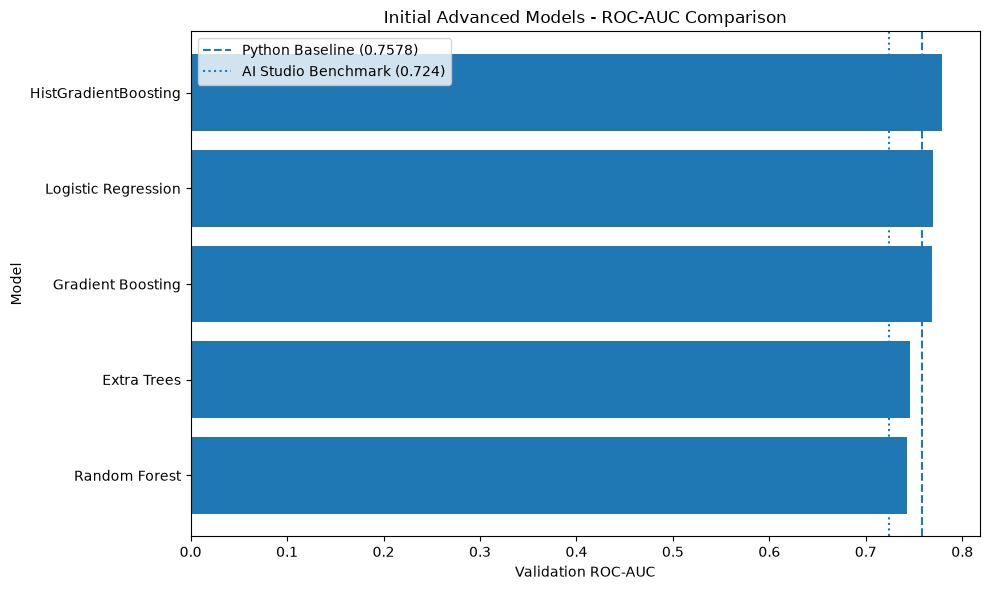

In [170]:
#ROC-AUC plot
initial_plot_data = initial_advanced_comparison.sort_values("Validation ROC-AUC", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(
    initial_plot_data["Model"],
    initial_plot_data["Validation ROC-AUC"]
)
plt.axvline(
    x=PYTHON_BASELINE_VALIDATION_AUC,
    linestyle="--",
    label="Python Baseline (0.7578)"
)
plt.axvline(
    x=AI_STUDIO_BENCHMARK_VALIDATION_AUC,
    linestyle=":",
    label="AI Studio Benchmark (0.724)"
)

plt.xlabel("Validation ROC-AUC")
plt.ylabel("Model")
plt.title("Initial Advanced Models - ROC-AUC Comparison")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "initial_advanced_models_roc_auc.png", dpi=300, bbox_inches="tight")
plt.show()

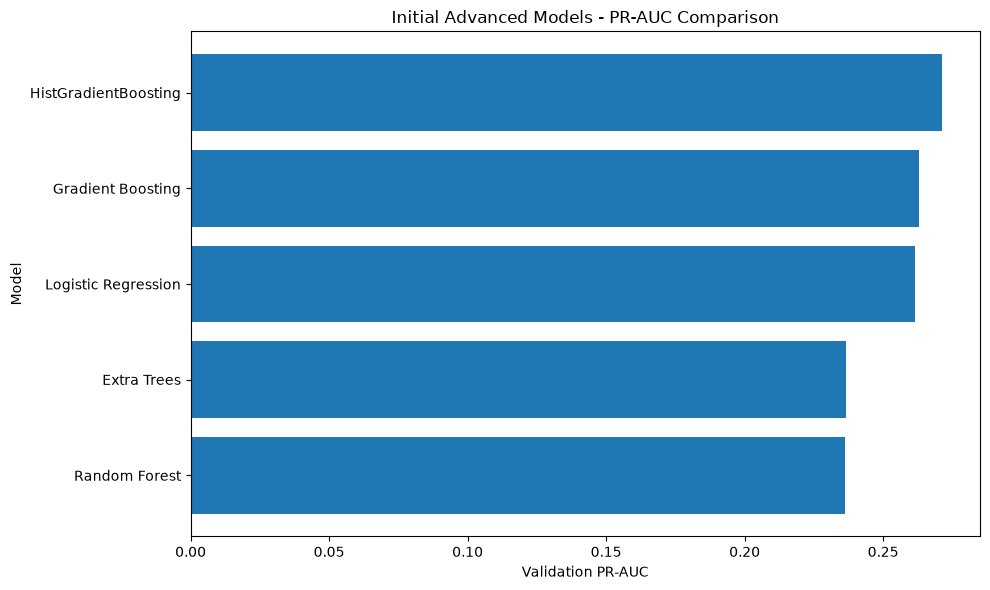

In [171]:
#PR-AUC plot
initial_pr_plot_data = initial_advanced_comparison.sort_values("Validation PR-AUC", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(initial_pr_plot_data["Model"], initial_pr_plot_data["Validation PR-AUC"])

plt.xlabel("Validation PR-AUC")
plt.ylabel("Model")
plt.title("Initial Advanced Models - PR-AUC Comparison")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "initial_advanced_models_pr_auc.png", dpi=300, bbox_inches="tight")
plt.show()

4.9 Comparison Against Previous Baselines

In [172]:
previous_reference_models = previous_python_baseline_results[["Model", "ROC-AUC", "PR-AUC"]].copy()
previous_reference_models = previous_reference_models.rename(columns={"ROC-AUC": "Validation ROC-AUC", "PR-AUC": "Validation PR-AUC"})
previous_reference_models["Stage"] = "Python Baseline"

current_reference_models = initial_advanced_comparison[["Model", "Validation ROC-AUC", "Validation PR-AUC"]].copy()
current_reference_models["Stage"] = "Advanced - Initial"

baseline_advanced_comparison = pd.concat([previous_reference_models, current_reference_models], ignore_index=True)
baseline_advanced_comparison = baseline_advanced_comparison.sort_values("Validation ROC-AUC", ascending=False).reset_index(drop=True)

baseline_advanced_comparison

,Model,Validation ROC-AUC,Validation PR-AUC,Stage
0,HistGradientBoosting,0.77943,0.271389,Advanced - Initial
1,Logistic Regression,0.769322,0.261664,Advanced - Initial
2,Gradient Boosting,0.768499,0.263087,Advanced - Initial
3,Gradient Boosting,0.7578,0.245777,Python Baseline
4,Logistic Regression,0.749211,0.236789,Python Baseline
5,Extra Trees,0.746266,0.23661,Advanced - Initial
6,Random Forest,0.742441,0.23621,Advanced - Initial
7,Random Forest,0.720081,0.210459,Python Baseline
8,Naive Bayes,0.557548,0.08948,Python Baseline
9,Decision Tree,0.536317,0.089994,Python Baseline


In [173]:
#Comparación específica de Gradient Boosting
gradient_boosting_feature_comparison = pd.DataFrame({
    "Representation": ["Baseline Features", "Advanced Features"],
    "Validation ROC-AUC": [PYTHON_BASELINE_VALIDATION_AUC, advanced_gb_results["Validation ROC-AUC"]]
})
gradient_boosting_feature_comparison

,Representation,Validation ROC-AUC
0,Baseline Features,0.757800
1,Advanced Features,0.768499


In [174]:
print("ROC-AUC change from advanced features:", round(advanced_gb_results["Validation ROC-AUC"] - PYTHON_BASELINE_VALIDATION_AUC, 6))

ROC-AUC change from advanced features: 0.010699


4.10 Initial Candidate Selection

In [175]:
initial_best_advanced_model = initial_advanced_comparison.iloc[0]

print("Best initial advanced model:", initial_best_advanced_model["Model"])
print("Validation ROC-AUC:", round(initial_best_advanced_model["Validation ROC-AUC"], 6))
print("Validation PR-AUC:", round(initial_best_advanced_model["Validation PR-AUC"], 6))
print("Difference vs Python baseline:", round(initial_best_advanced_model["Improvement vs Python Baseline"], 6))

Best initial advanced model: HistGradientBoosting
Validation ROC-AUC: 0.77943
Validation PR-AUC: 0.271389
Difference vs Python baseline: 0.02163


4.11 Export Candidate Results

In [176]:
initial_advanced_comparison.to_csv(RESULTS_DIR / "initial_advanced_model_results.csv", index=False)
baseline_advanced_comparison.to_csv(RESULTS_DIR / "baseline_vs_initial_advanced_models.csv", index=False)
gradient_boosting_feature_comparison.to_csv(RESULTS_DIR / "gradient_boosting_feature_comparison.csv", index=False)

## 5. Imbalance-Aware Modelling

5.1 Objective

The baseline and initial advanced modelling experiments demonstrated that strong ROC-AUC performance does not necessarily translate into effective detection of the minority positive class at the default classification threshold.

The target remains strongly imbalanced, with approximately 8% of observations belonging to `TARGET = 1`.

This section therefore evaluates imbalance-aware variants of the advanced candidate models.

The objective is not to optimise the classification threshold at this stage. Instead, the experiment investigates whether increasing the importance assigned to minority-class observations during model training can improve minority-class learning while maintaining strong probability-ranking performance.

The same train and validation partitions are retained, and no hyperparameter optimisation is introduced in this section.

5.2 Class Weighting Strategy

Class weighting is used as the first imbalance-aware strategy.

This approach was selected before introducing synthetic oversampling because it preserves the original observations and class distribution while modifying the importance assigned to minority-class errors during training.

For algorithms that directly support `class_weight`, the balanced weighting strategy is used.

For algorithms that do not expose an equivalent class-weight parameter, observation-level sample weights derived from the same balanced weighting calculation are supplied during model fitting.

This creates a consistent imbalance-aware experiment across the candidate models.

5.3 Sample Weight Preparation

In [177]:
train_sample_weights = y_train.map(CLASS_WEIGHT_BALANCED).to_numpy()

sample_weight_summary = pd.DataFrame({
    "TARGET": [0, 1],
    "Class Weight": [CLASS_WEIGHT_BALANCED[0], CLASS_WEIGHT_BALANCED[1]],
    "Training Observations": [int((y_train == 0).sum()), int((y_train == 1).sum())]
})
sample_weight_summary

,TARGET,Class Weight,Training Observations
0,0,0.543908,197880
1,1,6.193733,17377


The balanced weighting calculation assigns a larger training weight to observations belonging to the minority positive class.

The feature values and number of observations remain unchanged; only their contribution to the model-fitting objective is modified.

5.4 Logistic Regression — Balanced

In [178]:
balanced_logistic_regression = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)

#Fit
balanced_logistic_regression.fit(X_train_advanced_scaled, y_train)

#Evaluation
balanced_lr_validation_probability, balanced_lr_validation_prediction, balanced_lr_results = evaluate_advanced_model(
    model_name="Logistic Regression",
    configuration_name="Advanced Features - Balanced",
    model=balanced_logistic_regression,
    X_validation=X_validation_advanced_scaled,
    y_validation=y_validation
)
advanced_experiment_results = register_advanced_result(advanced_experiment_results, balanced_lr_results)
pd.DataFrame([balanced_lr_results])

,Experiment,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline
0,Logistic Regression - Advanced Features - Bala...,Logistic Regression,Advanced Features - Balanced,0.769185,0.259085,0.704902,0.172235,0.697637,0.276265,29917,12486,1126,2598,0.011385


5.5 Random Forest — Balanced

In [179]:
balanced_random_forest = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)

#Fit
balanced_random_forest.fit(X_train_advanced_unscaled, y_train)

#Evaluation
balanced_rf_validation_probability, balanced_rf_validation_prediction, balanced_rf_results = evaluate_advanced_model(
    model_name="Random Forest",
    configuration_name="Advanced Features - Balanced",
    model=balanced_random_forest,
    X_validation=X_validation_advanced_unscaled,
    y_validation=y_validation
)
advanced_experiment_results = register_advanced_result(advanced_experiment_results, balanced_rf_results)
pd.DataFrame([balanced_rf_results])

,Experiment,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline
0,Random Forest - Advanced Features - Balanced,Random Forest,Advanced Features - Balanced,0.760822,0.23542,0.916426,0.416561,0.087809,0.145043,41945,458,3397,327,0.003022


5.6 Extra Trees — Balanced

In [180]:
balanced_extra_trees = ExtraTreesClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)

#Fit
balanced_extra_trees.fit(X_train_advanced_unscaled, y_train)

#Evaluation
balanced_et_validation_probability, balanced_et_validation_prediction, balanced_et_results = evaluate_advanced_model(
    model_name="Extra Trees",
    configuration_name="Advanced Features - Balanced",
    model=balanced_extra_trees,
    X_validation=X_validation_advanced_unscaled,
    y_validation=y_validation
)
advanced_experiment_results = register_advanced_result(advanced_experiment_results, balanced_et_results)
pd.DataFrame([balanced_et_results])

,Experiment,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline
0,Extra Trees - Advanced Features - Balanced,Extra Trees,Advanced Features - Balanced,0.752185,0.2336,0.919245,0.478261,0.002954,0.005871,42391,12,3713,11,-0.005615


5.7 Gradient Boosting — Weighted

In [181]:
weighted_gradient_boosting = GradientBoostingClassifier(random_state=RANDOM_STATE)

#Fit con los pesos establecidos
weighted_gradient_boosting.fit(X_train_gb, y_train, sample_weight=train_sample_weights)

#Evaluation
weighted_gb_validation_probability, weighted_gb_validation_prediction, weighted_gb_results = evaluate_advanced_model(
    model_name="Gradient Boosting",
    configuration_name="Advanced Features - Weighted",
    model=weighted_gradient_boosting,
    X_validation=X_validation_gb,
    y_validation=y_validation
)
advanced_experiment_results = register_advanced_result(advanced_experiment_results, weighted_gb_results)
pd.DataFrame([weighted_gb_results])

,Experiment,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline
0,Gradient Boosting - Advanced Features - Weighted,Gradient Boosting,Advanced Features - Weighted,0.770921,0.261807,0.709411,0.173986,0.693609,0.278191,30140,12263,1141,2583,0.013121


5.8 HistGradientBoosting — Weighted

In [182]:
weighted_hist_gradient_boosting = HistGradientBoostingClassifier(random_state=RANDOM_STATE)

#Fit con los pesos establecidos
weighted_hist_gradient_boosting.fit(X_train_hist, y_train, sample_weight=train_sample_weights)

#Evaluation
weighted_hist_validation_probability, weighted_hist_validation_prediction, weighted_hist_results = evaluate_advanced_model(
    model_name="HistGradientBoosting",
    configuration_name="Advanced Features - Weighted",
    model=weighted_hist_gradient_boosting,
    X_validation=X_validation_hist,
    y_validation=y_validation
)
advanced_experiment_results = register_advanced_result(advanced_experiment_results, weighted_hist_results)
pd.DataFrame([weighted_hist_results])

,Experiment,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline
0,HistGradientBoosting - Advanced Features - Wei...,HistGradientBoosting,Advanced Features - Weighted,0.779601,0.274897,0.728706,0.184358,0.689313,0.290911,31046,11357,1157,2567,0.021801


5.9 Imbalance-Aware Model Comparison

In [183]:
#Seleccionamos los 5 nuevos modelos
imbalance_aware_results = advanced_experiment_results[advanced_experiment_results["Configuration"].str.contains("Balanced|Weighted", regex=True)].copy()

imbalance_aware_results = imbalance_aware_results.sort_values("Validation ROC-AUC", ascending=False).reset_index(drop=True)

imbalance_aware_results.insert(0, "Validation Rank", range(1, len(imbalance_aware_results) + 1))

imbalance_aware_results[
    [
        "Validation Rank",
        "Model",
        "Configuration",
        "Validation ROC-AUC",
        "Validation PR-AUC",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "TN",
        "FP",
        "FN",
        "TP",
        "Improvement vs Python Baseline"
    ]
]

,Validation Rank,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline
0,1,HistGradientBoosting,Advanced Features - Weighted,0.779601,0.274897,0.728706,0.184358,0.689313,0.290911,31046,11357,1157,2567,0.021801
1,2,Gradient Boosting,Advanced Features - Weighted,0.770921,0.261807,0.709411,0.173986,0.693609,0.278191,30140,12263,1141,2583,0.013121
2,3,Logistic Regression,Advanced Features - Balanced,0.769185,0.259085,0.704902,0.172235,0.697637,0.276265,29917,12486,1126,2598,0.011385
3,4,Random Forest,Advanced Features - Balanced,0.760822,0.23542,0.916426,0.416561,0.087809,0.145043,41945,458,3397,327,0.003022
4,5,Extra Trees,Advanced Features - Balanced,0.752185,0.2336,0.919245,0.478261,0.002954,0.005871,42391,12,3713,11,-0.005615


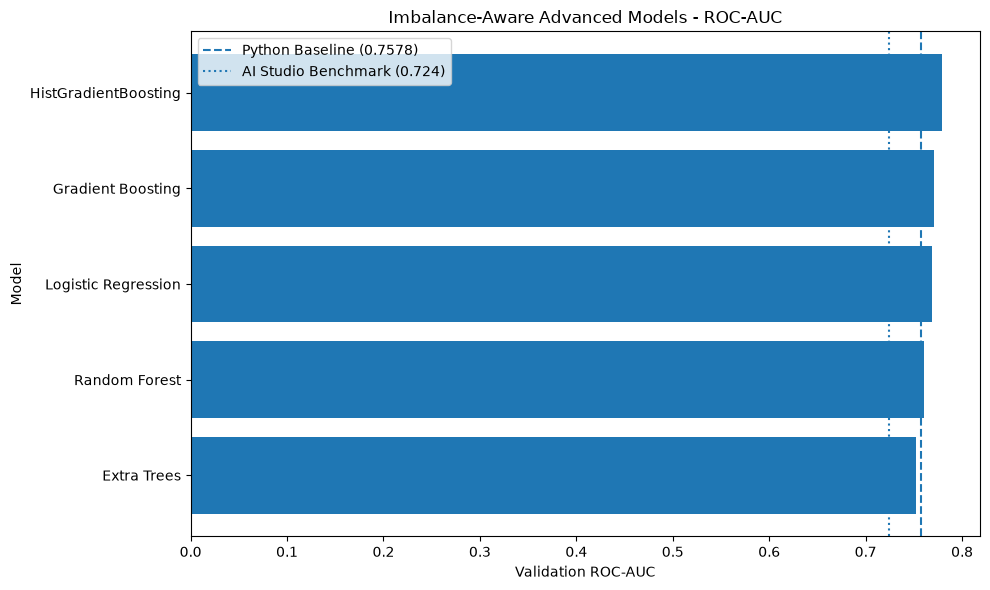

In [184]:
#ROC-AUC comparison
imbalance_roc_plot = imbalance_aware_results.sort_values("Validation ROC-AUC", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(imbalance_roc_plot["Model"], imbalance_roc_plot["Validation ROC-AUC"])

plt.axvline(
    x=PYTHON_BASELINE_VALIDATION_AUC,
    linestyle="--",
    label="Python Baseline (0.7578)"
)
plt.axvline(
    x=AI_STUDIO_BENCHMARK_VALIDATION_AUC,
    linestyle=":",
    label="AI Studio Benchmark (0.724)"
)

plt.xlabel("Validation ROC-AUC")
plt.ylabel("Model")
plt.title("Imbalance-Aware Advanced Models - ROC-AUC")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "imbalance_aware_models_roc_auc.png", dpi=300, bbox_inches="tight")
plt.show()

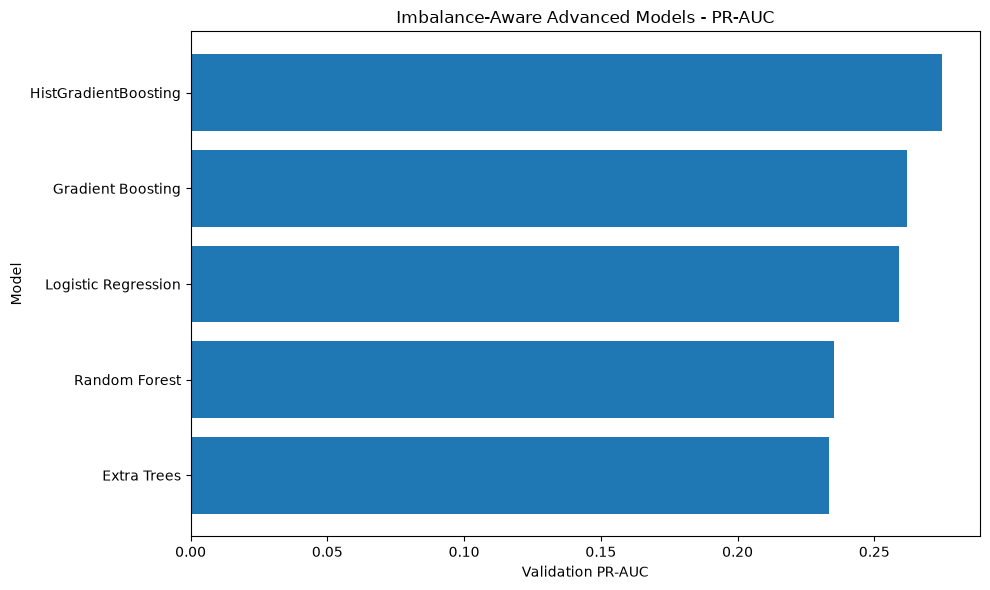

In [185]:
#PR-AUC comparison
imbalance_pr_plot = imbalance_aware_results.sort_values("Validation PR-AUC", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(imbalance_pr_plot["Model"], imbalance_pr_plot["Validation PR-AUC"])

plt.xlabel("Validation PR-AUC")
plt.ylabel("Model")
plt.title("Imbalance-Aware Advanced Models - PR-AUC")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "imbalance_aware_models_pr_auc.png", dpi=300, bbox_inches="tight")
plt.show()

5.10 Default vs Imbalance-Aware Comparison

Queremos poder responder: ¿Qué le ocurrió a cada algoritmo cuando introdujimos weighting?

In [186]:
#Construimos los defaults
default_advanced_results = advanced_experiment_results[advanced_experiment_results["Configuration"] == "Advanced Features - Default"].copy()

In [187]:
#Version completa
default_comparison = (
    default_advanced_results[
        [
            "Model",
            "Validation ROC-AUC",
            "Validation PR-AUC",
            "Precision",
            "Recall",
            "F1"
        ]
    ]
    .rename(
        columns={
            "Validation ROC-AUC":
                "Default ROC-AUC",
            "Validation PR-AUC":
                "Default PR-AUC",
            "Precision":
                "Default Precision",
            "Recall":
                "Default Recall",
            "F1":
                "Default F1"
        }
    )
)

In [188]:
#Weighted
weighted_comparison = (
    imbalance_aware_results[
        [
            "Model",
            "Validation ROC-AUC",
            "Validation PR-AUC",
            "Precision",
            "Recall",
            "F1"
        ]
    ]
    .rename(
        columns={
            "Validation ROC-AUC":
                "Weighted ROC-AUC",
            "Validation PR-AUC":
                "Weighted PR-AUC",
            "Precision":
                "Weighted Precision",
            "Recall":
                "Weighted Recall",
            "F1":
                "Weighted F1"
        }
    )
)

In [189]:
#Mergeamos ambas
default_vs_weighted = pd.merge(
    default_comparison,
    weighted_comparison,
    on="Model",
    how="inner"
)

In [190]:
#Calculamos cambios
default_vs_weighted["ROC-AUC Change"] = default_vs_weighted["Weighted ROC-AUC"] - default_vs_weighted["Default ROC-AUC"]
default_vs_weighted["PR-AUC Change"] = default_vs_weighted["Weighted PR-AUC"] - default_vs_weighted["Default PR-AUC"]
default_vs_weighted["Recall Change"] = default_vs_weighted["Weighted Recall"] - default_vs_weighted["Default Recall"]
default_vs_weighted["F1 Change"] = default_vs_weighted["Weighted F1"] - default_vs_weighted["Default F1"]

default_vs_weighted.sort_values("Weighted ROC-AUC", ascending=False)

,Model,Default ROC-AUC,Default PR-AUC,Default Precision,Default Recall,Default F1,Weighted ROC-AUC,Weighted PR-AUC,Weighted Precision,Weighted Recall,Weighted F1,ROC-AUC Change,PR-AUC Change,Recall Change,F1 Change
3,HistGradientBoosting,0.77943,0.271389,0.53629,0.035714,0.066969,0.779601,0.274897,0.184358,0.689313,0.290911,0.000171,0.003508,0.653598,0.223942
1,Gradient Boosting,0.768499,0.263087,0.664384,0.026047,0.050129,0.770921,0.261807,0.173986,0.693609,0.278191,0.002422,-0.00128,0.667562,0.228061
0,Logistic Regression,0.769322,0.261664,0.584112,0.033566,0.063484,0.769185,0.259085,0.172235,0.697637,0.276265,-0.000137,-0.002579,0.664071,0.212781
4,Random Forest,0.742441,0.23621,0.75,0.00725,0.014362,0.760822,0.23542,0.416561,0.087809,0.145043,0.018381,-0.00079,0.080559,0.130682
2,Extra Trees,0.746266,0.23661,0.875,0.00188,0.003751,0.752185,0.2336,0.478261,0.002954,0.005871,0.005919,-0.00301,0.001074,0.00212


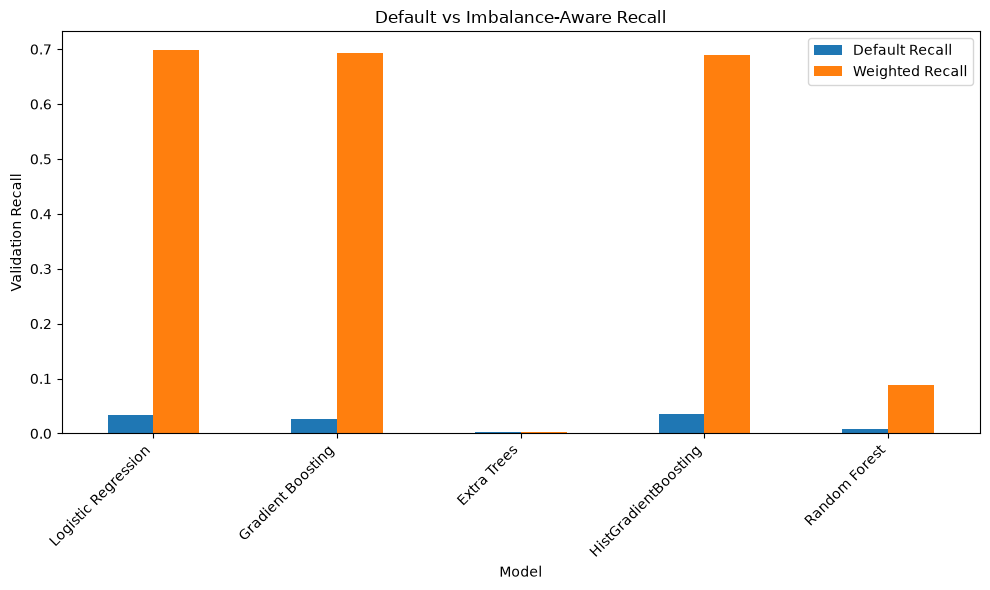

In [191]:
#Recall comparison plot
recall_comparison_plot = default_vs_weighted[["Model", "Default Recall", "Weighted Recall"]].set_index("Model")

recall_comparison_plot.plot(kind="bar", figsize=(10, 6))
plt.ylabel("Validation Recall")
plt.xlabel("Model")
plt.title("Default vs Imbalance-Aware Recall")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "default_vs_weighted_recall.png", dpi=300, bbox_inches="tight")
plt.show()

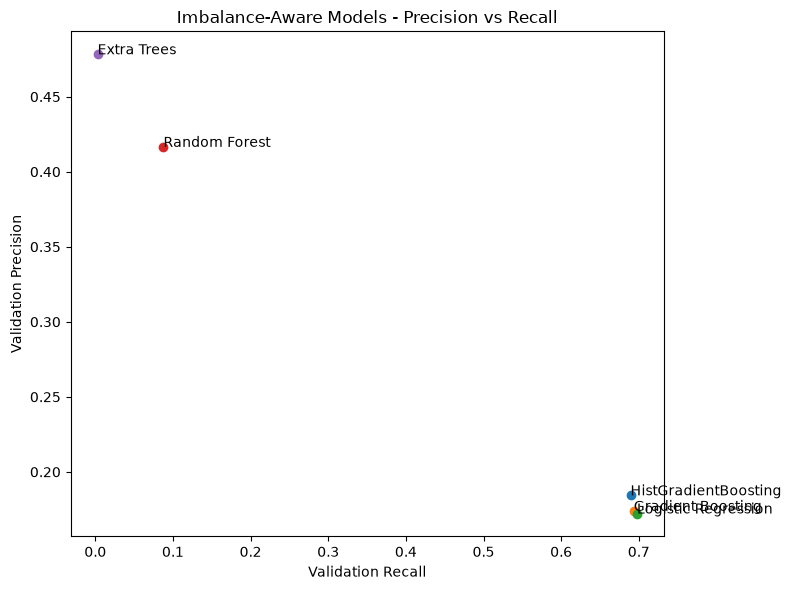

In [192]:
#Precision vs Recall
plt.figure(figsize=(8, 6))

for _, row in imbalance_aware_results.iterrows():
    plt.scatter(row["Recall"], row["Precision"])
    plt.annotate(row["Model"], (row["Recall"], row["Precision"]))
    
plt.xlabel("Validation Recall")
plt.ylabel("Validation Precision")
plt.title("Imbalance-Aware Models - Precision vs Recall")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "imbalance_precision_recall_tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()

5.11 Candidate Selection for Hyperparameter Tuning

In [193]:
#Select top3 by ROC-AUC
top_imbalance_candidates = imbalance_aware_results.head(3).copy()

top_imbalance_candidates[
    [
        "Model",
        "Validation ROC-AUC",
        "Validation PR-AUC",
        "Precision",
        "Recall",
        "F1"
    ]
]

,Model,Validation ROC-AUC,Validation PR-AUC,Precision,Recall,F1
0,HistGradientBoosting,0.779601,0.274897,0.184358,0.689313,0.290911
1,Gradient Boosting,0.770921,0.261807,0.173986,0.693609,0.278191
2,Logistic Regression,0.769185,0.259085,0.172235,0.697637,0.276265


In [194]:
#Creamos el ranking de todos los modelos hasta ahora
all_advanced_results_ranked = advanced_experiment_results.sort_values("Validation ROC-AUC", ascending=False).reset_index(drop=True).copy()

all_advanced_results_ranked.insert(0, "Overall Rank", range(1, len(all_advanced_results_ranked) + 1))
all_advanced_results_ranked[
    [
        "Overall Rank",
        "Model",
        "Configuration",
        "Validation ROC-AUC",
        "Validation PR-AUC",
        "Precision",
        "Recall",
        "F1",
        "Improvement vs Python Baseline"
    ]
]

,Overall Rank,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Precision,Recall,F1,Improvement vs Python Baseline
0,1,HistGradientBoosting,Advanced Features - Weighted,0.779601,0.274897,0.184358,0.689313,0.290911,0.021801
1,2,HistGradientBoosting,Advanced Features - Default,0.77943,0.271389,0.53629,0.035714,0.066969,0.02163
2,3,Gradient Boosting,Advanced Features - Weighted,0.770921,0.261807,0.173986,0.693609,0.278191,0.013121
3,4,Logistic Regression,Advanced Features - Default,0.769322,0.261664,0.584112,0.033566,0.063484,0.011522
4,5,Logistic Regression,Advanced Features - Balanced,0.769185,0.259085,0.172235,0.697637,0.276265,0.011385
5,6,Gradient Boosting,Advanced Features - Default,0.768499,0.263087,0.664384,0.026047,0.050129,0.010699
6,7,Random Forest,Advanced Features - Balanced,0.760822,0.23542,0.416561,0.087809,0.145043,0.003022
7,8,Extra Trees,Advanced Features - Balanced,0.752185,0.2336,0.478261,0.002954,0.005871,-0.005615
8,9,Extra Trees,Advanced Features - Default,0.746266,0.23661,0.875,0.00188,0.003751,-0.011534
9,10,Random Forest,Advanced Features - Default,0.742441,0.23621,0.75,0.00725,0.014362,-0.015359


5.12 Export Results & Conclusions

In [195]:
#Export results
imbalance_aware_results.to_csv(RESULTS_DIR / "imbalance_aware_model_results.csv", index=False)
default_vs_weighted.to_csv(RESULTS_DIR / "default_vs_imbalance_aware_comparison.csv", index=False)
all_advanced_results_ranked.to_csv(RESULTS_DIR / "all_advanced_experiments_before_tuning.csv", index=False)

The imbalance aware experiments demonstrated that increasing the importance assigned to the minority positive class can substantially change classification behaviour without necessarily degrading probability-ranking performance.

The strongest overall configuration was **weighted HistGradientBoosting**, which achieved a validation ROC-AUC of **0.7796** and PR-AUC of **0.2749**. This represents an improvement of approximately **0.0218 ROC-AUC points** over the previous Python baseline of 0.7578.

Importantly, the weighted HistGradientBoosting configuration produced almost the same ROC-AUC as its default counterpart (0.7796 versus 0.7794), while increasing Recall from approximately **0.0357 to 0.6893**. Its F1-score consequently increased from approximately **0.0670 to 0.2909**.

A similar effect was observed for Gradient Boosting. Weighting increased validation ROC-AUC from **0.7685 to 0.7709** and increased Recall from approximately **0.0260 to 0.6936**.

Logistic Regression also showed a substantial change in threshold-dependent behaviour. Its ROC-AUC remained almost unchanged (0.7693 default versus 0.7692 balanced), while Recall increased from approximately **0.0336 to 0.6976**.

These results demonstrate that class weighting primarily affected the operating behaviour of the classifiers rather than fundamentally changing their ranking ability. In several cases, a large increase in Recall was accompanied by a reduction in Precision, illustrating the expected trade-off when greater importance is assigned to the minority class.

Random Forest benefited from class weighting in terms of ROC-AUC, improving from approximately **0.7424 to 0.7608**, but remained below the leading boosting and linear models.

Extra Trees remained below the previous Python baseline after weighting and was therefore not prioritised for further optimisation.

Based on the combined evidence from ROC-AUC, PR-AUC and minority-class behaviour, the models carried forward to hyperparameter optimisation are:

- **HistGradientBoosting**

- **Gradient Boosting**

- **Logistic Regression**

HistGradientBoosting is the strongest candidate overall, Gradient Boosting provides continuity with the previous benchmark architecture, and Logistic Regression is retained because of its strong discrimination and comparatively simple and interpretable structure.

Random Forest and Extra Trees are not prioritised for hyperparameter optimisation because their validation performance is materially weaker than the leading candidates.

Threshold optimisation remains deferred until the Evaluation stage.

## 6. Hyperparameter Optimisation

6.1 Optimisation Objective

The previous experiments identified HistGradientBoosting, Gradient Boosting and Logistic Regression as the strongest candidates for further optimisation.

The objective of this section is to determine whether controlled hyperparameter optimisation can improve model discrimination beyond the performance achieved by the initial advanced configurations.

Hyperparameter optimisation is performed exclusively on the training partition using 5-fold Stratified Cross-Validation.

The optimisation criterion remains **ROC-AUC**.

The fixed validation partition does not participate in the search process and will only be used in the subsequent section to evaluate the optimised configurations.

The internal test partition remains completely untouched.

6.2 Candidate Selection

Only the strongest models identified during the previous experimental stages are carried forward to hyperparameter optimisation.

HistGradientBoosting is prioritised because it currently provides the strongest overall validation performance.

Gradient Boosting is retained because both its default and weighted configurations improved upon the previous Python baseline.

Logistic Regression is also retained because it achieved competitive ROC-AUC despite its substantially simpler model structure.

Random Forest and Extra Trees are excluded from tuning because their validation performance was materially weaker than the selected candidates.

In [196]:
tuning_candidates = pd.DataFrame({
    "Model": [
        "HistGradientBoosting",
        "Gradient Boosting",
        "Logistic Regression"
    ],
    "Reason for Selection": [
        "Highest overall validation ROC-AUC and PR-AUC before tuning",
        "Strong weighted performance and continuity with previous boosting benchmark", 
        "Strong discrimination with simpler and more interpretable model structure"
    ]
})
tuning_candidates

,Model,Reason for Selection
0,HistGradientBoosting,Highest overall validation ROC-AUC and PR-AUC ...
1,Gradient Boosting,Strong weighted performance and continuity wit...
2,Logistic Regression,Strong discrimination with simpler and more in...


6.3 Search Design

In [197]:
print("Cross-validation folds:", CV_FOLDS)
print("Optimisation metric:", HYPERPARAMETER_SCORING)
print("Random search iterations:", N_ITER_RANDOM_SEARCH)
print("Random state:", RANDOM_STATE)

Cross-validation folds: 5
Optimisation metric: roc_auc
Random search iterations: 20
Random state: 1992


`RandomizedSearchCV` is used as the primary hyperparameter optimisation strategy.

An exhaustive grid search becomes computationally expensive when several parameters and candidate values are evaluated simultaneously, particularly with a large training dataset and five-fold cross-validation.

Randomised search allows a broader region of the parameter space to be explored using a controlled computational budget.

Each sampled configuration is evaluated using the same stratified cross-validation folds and ROC-AUC scoring criterion.

A fixed random state ensures that the sampled parameter combinations can be reproduced.

6.4 HistGradientBoosting Search Space

Tunning del modelo HistGradientBoosting

In [198]:
hist_gb_tuning_model = HistGradientBoostingClassifier(random_state=RANDOM_STATE)

#Definir el espacio de búsqueda de hyperparameters
hist_gb_param_distributions = {
    "learning_rate": [0.03, 0.05, 0.08, 0.10, 0.15],
    "max_iter": [100, 150, 200, 250, 300],
    "max_leaf_nodes": [15, 31, 63],
    "max_depth": [None, 5, 10, 15],
    "min_samples_leaf": [10, 20, 30, 50],
    "l2_regularization": [0.0, 0.1, 0.5, 1.0, 2.0]
}

6.5 HistGradientBoosting RandomizedSearchCV

In [199]:
#Model
hist_gb_random_search = RandomizedSearchCV(
    estimator=hist_gb_tuning_model,
    param_distributions=hist_gb_param_distributions,
    n_iter=N_ITER_RANDOM_SEARCH,
    scoring=HYPERPARAMETER_SCORING,
    cv=stratified_cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

#Train
hist_gb_random_search.fit(X_train_hist, y_train, sample_weight=train_sample_weights)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",HistGradientB...om_state=1992)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'l2_regularization': [0.0, 0.1, ...], 'learning_rate': [0.03, 0.05, ...], 'max_depth': [None, 5, ...], 'max_iter': [100, 150, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",1992
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly requir

In [200]:
print("Best CV ROC-AUC:", hist_gb_random_search.best_score_)
print("Best parameters:")

hist_gb_random_search.best_params_

Best CV ROC-AUC: 0.7770195695420397
Best parameters:


{'min_samples_leaf': 30,
 'max_leaf_nodes': 15,
 'max_iter': 200,
 'max_depth': 10,
 'learning_rate': 0.08,
 'l2_regularization': 1.0}

In [201]:
hist_gb_cv_results = pd.DataFrame(hist_gb_random_search.cv_results_)
hist_gb_cv_results = hist_gb_cv_results.sort_values("rank_test_score").reset_index(drop=True)
hist_gb_cv_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "std_train_score",
        "params"
    ]
].head(10)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
0,1,0.777020,0.002422,0.813342,0.003431,"{'min_samples_leaf': 30, 'max_leaf_nodes': 15,..."
1,2,0.776647,0.002398,0.835407,0.001867,"{'min_samples_leaf': 10, 'max_leaf_nodes': 31,..."
2,3,0.776388,0.002128,0.835428,0.001996,"{'min_samples_leaf': 20, 'max_leaf_nodes': 31,..."
3,4,0.775969,0.001916,0.808472,0.000805,"{'min_samples_leaf': 20, 'max_leaf_nodes': 15,..."
4,5,0.775890,0.002398,0.811678,0.007062,"{'min_samples_leaf': 10, 'max_leaf_nodes': 15,..."
5,6,0.775837,0.001739,0.831738,0.002647,"{'min_samples_leaf': 50, 'max_leaf_nodes': 31,..."
6,7,0.775749,0.002102,0.856963,0.003696,"{'min_samples_leaf': 20, 'max_leaf_nodes': 63,..."
7,8,0.775674,0.002459,0.833208,0.004868,"{'min_samples_leaf': 50, 'max_leaf_nodes': 31,..."
8,9,0.775465,0.001691,0.801317,0.000267,"{'min_samples_leaf': 10, 'max_leaf_nodes': 15,..."
9,10,0.775296,0.001856,0.801265,0.000314,"{'min_samples_leaf': 20, 'max_leaf_nodes': 15,..."


In [202]:
#Comprobar train vs cv
hist_gb_best_cv_row = hist_gb_cv_results.iloc[0]

print("Mean training ROC-AUC:", round(hist_gb_best_cv_row["mean_train_score"], 6))
print("Mean CV ROC-AUC:", round(hist_gb_best_cv_row["mean_test_score"], 6))
print("Train-CV gap:", round(hist_gb_best_cv_row["mean_train_score"] - hist_gb_best_cv_row["mean_test_score"], 6))

Mean training ROC-AUC: 0.813342
Mean CV ROC-AUC: 0.77702
Train-CV gap: 0.036322


In [203]:
#Guardar tunning HistGradientBoosting e hyperparameters
hist_gb_cv_results.to_csv(TUNING_DIR / "hist_gradient_boosting_random_search.csv", index=False)
with open(TUNING_DIR / "hist_gradient_boosting_best_params.json", "w") as file:
    json.dump(hist_gb_random_search.best_params_, file, indent=4)

tuned_hist_gradient_boosting = hist_gb_random_search.best_estimator_

6.6 Gradient Boosting Search Space

Tunning del modelo Gradient Boosting

In [206]:
gradient_boosting_tuning_model = GradientBoostingClassifier(random_state=RANDOM_STATE)

#Definir el espacio de búsqueda de hyperparameters
gradient_boosting_param_distributions = {
    "n_estimators": [100, 150, 200, 250],
    "learning_rate": [0.03, 0.05, 0.08, 0.10],
    "min_samples_split": [2, 10, 20, 30],
    "max_depth": [2, 3, 4, 5],
    "min_samples_leaf": [1, 10, 20, 30],
    "subsample": [0.7, 0.8, 0.9, 1.0]
}

6.7 Gradient Boosting RandomizedSearchCV

In [207]:
#Model
gradient_boosting_random_search = RandomizedSearchCV(
    estimator=gradient_boosting_tuning_model,
    param_distributions=gradient_boosting_param_distributions,
    n_iter=N_ITER_RANDOM_SEARCH,
    scoring=HYPERPARAMETER_SCORING,
    cv=stratified_cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

#Train
gradient_boosting_random_search.fit(X_train_gb, y_train, sample_weight=train_sample_weights)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoost...om_state=1992)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'learning_rate': [0.03, 0.05, ...], 'max_depth': [2, 3, ...], 'min_samples_leaf': [1, 10, ...], 'min_samples_split': [2, 10, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",1992
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly require

In [208]:
print("Best CV ROC-AUC:", gradient_boosting_random_search.best_score_)
print("Best parameters:")
gradient_boosting_random_search.best_params_

Best CV ROC-AUC: 0.7779499845777897
Best parameters:


{'subsample': 0.8,
 'n_estimators': 250,
 'min_samples_split': 2,
 'min_samples_leaf': 1,
 'max_depth': 3,
 'learning_rate': 0.1}

In [209]:
gradient_boosting_cv_results = pd.DataFrame(gradient_boosting_random_search.cv_results_)
gradient_boosting_cv_results = gradient_boosting_cv_results.sort_values("rank_test_score").reset_index(drop=True)
gradient_boosting_cv_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "std_train_score",
        "params"
    ]
].head(10)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
0,1,0.777950,0.002024,0.807668,0.000501,"{'subsample': 0.8, 'n_estimators': 250, 'min_s..."
1,2,0.776880,0.002541,0.869783,0.000715,"{'subsample': 0.8, 'n_estimators': 250, 'min_s..."
2,3,0.776327,0.002838,0.869042,0.000700,"{'subsample': 0.8, 'n_estimators': 250, 'min_s..."
3,4,0.775937,0.002784,0.842845,0.000713,"{'subsample': 1.0, 'n_estimators': 150, 'min_s..."
4,5,0.775459,0.002296,0.828917,0.000830,"{'subsample': 1.0, 'n_estimators': 200, 'min_s..."
5,6,0.775068,0.001918,0.796176,0.000277,"{'subsample': 0.8, 'n_estimators': 200, 'min_s..."
6,7,0.774038,0.002153,0.803076,0.000435,"{'subsample': 0.8, 'n_estimators': 100, 'min_s..."
7,8,0.771250,0.001820,0.782644,0.000351,"{'subsample': 0.8, 'n_estimators': 200, 'min_s..."
8,9,0.771123,0.002300,0.786044,0.000476,"{'subsample': 0.7, 'n_estimators': 200, 'min_s..."
9,10,0.770019,0.002591,0.803390,0.000190,"{'subsample': 0.8, 'n_estimators': 100, 'min_s..."


In [210]:
#Comprobar train vs cv
gradient_boosting_best_cv_row = gradient_boosting_cv_results.iloc[0]

print("Mean training ROC-AUC:", round(gradient_boosting_best_cv_row["mean_train_score"], 6))
print("Mean CV ROC-AUC:", round(gradient_boosting_best_cv_row["mean_test_score"], 6))
print("Train-CV gap:", round(gradient_boosting_best_cv_row["mean_train_score"] - gradient_boosting_best_cv_row["mean_test_score"], 6))

Mean training ROC-AUC: 0.807668
Mean CV ROC-AUC: 0.77795
Train-CV gap: 0.029718


In [211]:
#Guardar tunning Gradient Boosting e hyperparameters
gradient_boosting_cv_results.to_csv(TUNING_DIR / "gradient_boosting_random_search.csv", index=False)
with open(TUNING_DIR / "gradient_boosting_best_params.json", "w") as file:
    json.dump(gradient_boosting_random_search.best_params_, file, indent=4)

tuned_gradient_boosting = gradient_boosting_random_search.best_estimator_

6.8 Logistic Regression Search Space

In [212]:
logistic_regression_tuning_model = LogisticRegression(class_weight="balanced", random_state=RANDOM_STATE, max_iter=2000)

#Definir el espacio de busqueda de hyperparameters
logistic_regression_param_distributions = {
    "C": [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear", "saga"]
}

C pequeño
→ regularización más fuerte

C grande
→ regularización más débil

L1
→ puede llevar coeficientes exactamente a 0
→ potencial selección implícita de variables

L2
→ reduce coeficientes sin eliminarlos necesariamente

6.9 Logistic Regression RandomizedSearchCV

In [213]:
#Model
logistic_regression_random_search = RandomizedSearchCV(
    estimator=logistic_regression_tuning_model,
    param_distributions=logistic_regression_param_distributions,
    n_iter=N_ITER_RANDOM_SEARCH,
    scoring=HYPERPARAMETER_SCORING,
    cv=stratified_cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

#Train
logistic_regression_random_search.fit(X_train_advanced_scaled, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...om_state=1992)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'C': [0.001, 0.005, ...], 'penalty': ['l1', 'l2'], 'solver': ['liblinear', 'saga']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",1992
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best genera

In [214]:
print("Best CV ROC-AUC:", logistic_regression_random_search.best_score_)
print("Best parameters:")
logistic_regression_random_search.best_params_

Best CV ROC-AUC: 0.7697696454607161
Best parameters:


{'solver': 'liblinear', 'penalty': 'l1', 'C': 0.05}

In [215]:
logistic_regression_cv_results = pd.DataFrame(logistic_regression_random_search.cv_results_)
logistic_regression_cv_results = logistic_regression_cv_results.sort_values("rank_test_score").reset_index(drop=True)
logistic_regression_cv_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "std_train_score",
        "params"
    ]
].head(10)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
0,1,0.769770,0.002188,0.774108,0.000575,"{'solver': 'liblinear', 'penalty': 'l1', 'C': ..."
1,2,0.769546,0.002193,0.774281,0.000550,"{'solver': 'saga', 'penalty': 'l1', 'C': 0.1}"
2,3,0.769478,0.002133,0.774784,0.000568,"{'solver': 'liblinear', 'penalty': 'l2', 'C': ..."
3,4,0.769402,0.002205,0.774067,0.000563,"{'solver': 'liblinear', 'penalty': 'l2', 'C': ..."
4,5,0.769380,0.002139,0.774499,0.000554,"{'solver': 'saga', 'penalty': 'l2', 'C': 0.05}"
5,6,0.769343,0.002115,0.774572,0.000557,"{'solver': 'saga', 'penalty': 'l1', 'C': 0.5}"
6,7,0.769332,0.002117,0.774569,0.000555,"{'solver': 'saga', 'penalty': 'l2', 'C': 0.1}"
7,8,0.769284,0.002219,0.773875,0.000544,"{'solver': 'saga', 'penalty': 'l2', 'C': 0.01}"
8,9,0.769283,0.002097,0.774611,0.000558,"{'solver': 'saga', 'penalty': 'l1', 'C': 2.0}"
9,10,0.769270,0.002093,0.774618,0.000558,"{'solver': 'saga', 'penalty': 'l1', 'C': 5.0}"


In [216]:
#Comprobar train vs cv
logistic_regression_best_cv_row = logistic_regression_cv_results.iloc[0]

print("Mean training ROC-AUC:", round(logistic_regression_best_cv_row["mean_train_score"], 6))
print("Mean CV ROC-AUC:", round(logistic_regression_best_cv_row["mean_test_score"], 6))
print("Train-CV gap:", round(logistic_regression_best_cv_row["mean_train_score"] - logistic_regression_best_cv_row["mean_test_score"], 6))

Mean training ROC-AUC: 0.774108
Mean CV ROC-AUC: 0.76977
Train-CV gap: 0.004339


In [217]:
#Save results
logistic_regression_cv_results.to_csv(TUNING_DIR / "logistic_regression_random_search.csv", index=False)
with open(TUNING_DIR / "logistic_regression_best_params.json", "w") as file:
    json.dump(logistic_regression_random_search.best_params_, file, indent=4)

tuned_logistic_regression = logistic_regression_random_search.best_estimator_

6.10 Cross-Validation Search Results

In [218]:
tuning_cv_summary = pd.DataFrame({
    "Model": [
        "HistGradientBoosting",
        "Gradient Boosting",
        "Logistic Regression"
    ],
    "Best CV ROC-AUC": [
        hist_gb_random_search.best_score_,
        gradient_boosting_random_search.best_score_,
        logistic_regression_random_search.best_score_
    ],
    "Mean Train ROC-AUC": [
        hist_gb_best_cv_row["mean_train_score"],
        gradient_boosting_best_cv_row["mean_train_score"],
        logistic_regression_best_cv_row["mean_train_score"]
    ]
})

In [219]:
tuning_cv_summary["Train-CV Gap"] = (tuning_cv_summary["Mean Train ROC-AUC"] - tuning_cv_summary["Best CV ROC-AUC"])
tuning_cv_summary = tuning_cv_summary.sort_values("Best CV ROC-AUC", ascending=False).reset_index(drop=True)
tuning_cv_summary.insert(0, "CV Rank", range(1, len(tuning_cv_summary) + 1))

tuning_cv_summary

,CV Rank,Model,Best CV ROC-AUC,Mean Train ROC-AUC,Train-CV Gap
0,1,Gradient Boosting,0.77795,0.807668,0.029718
1,2,HistGradientBoosting,0.77702,0.813342,0.036322
2,3,Logistic Regression,0.76977,0.774108,0.004339


The three selected candidate models were optimised independently using the same 5-fold Stratified Cross-Validation procedure and ROC-AUC objective.

Gradient Boosting achieved the strongest mean cross-validation ROC-AUC of approximately **0.7780**, narrowly outperforming HistGradientBoosting at approximately **0.7770**.

Logistic Regression achieved a lower mean cross-validation ROC-AUC of approximately **0.7698**, although its training and cross-validation scores were considerably closer.

The train-CV gap was approximately:

- Gradient Boosting: **0.0297**

- HistGradientBoosting: **0.0363**

- Logistic Regression: **0.0043**

This indicates that Logistic Regression produced the most similar training and cross-validation performance, consistent with its lower model complexity.

The two boosting methods achieved stronger discrimination but exhibited larger differences between training and cross-validation performance.

These cross-validation results are used to assess the optimisation process only. The tuned models have not yet been compared using the fixed validation partition.

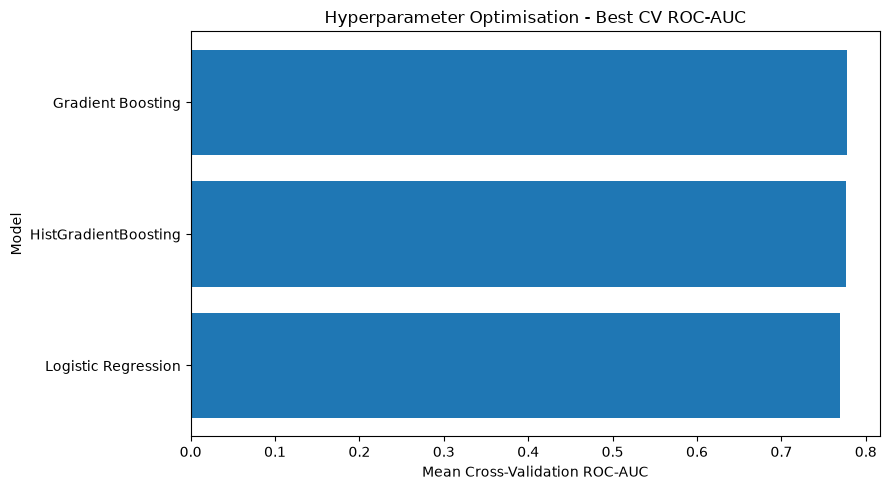

In [220]:
#Gráfico CV
tuning_cv_plot_data = tuning_cv_summary.sort_values("Best CV ROC-AUC", ascending=True)
plt.figure(figsize=(9, 5))
plt.barh(tuning_cv_plot_data["Model"], tuning_cv_plot_data["Best CV ROC-AUC"])
plt.xlabel("Mean Cross-Validation ROC-AUC")
plt.ylabel("Model")
plt.title("Hyperparameter Optimisation - Best CV ROC-AUC")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tuning_best_cv_roc_auc.png", dpi=300, bbox_inches="tight")
plt.show()

6.11 Best Hyperparameter Configurations

In [221]:
best_hyperparameters_summary = pd.DataFrame({
    "Model": [
        "HistGradientBoosting",
        "Gradient Boosting",
        "Logistic Regression"
    ],
    "Best Parameters": [
        hist_gb_random_search.best_params_,
        gradient_boosting_random_search.best_params_,
        logistic_regression_random_search.best_params_
    ],
    "Best CV ROC-AUC": [
        hist_gb_random_search.best_score_,
        gradient_boosting_random_search.best_score_,
        logistic_regression_random_search.best_score_
    ]
})

best_hyperparameters_summary

,Model,Best Parameters,Best CV ROC-AUC
0,HistGradientBoosting,"{'min_samples_leaf': 30, 'max_leaf_nodes': 15,...",0.77702
1,Gradient Boosting,"{'subsample': 0.8, 'n_estimators': 250, 'min_s...",0.77795
2,Logistic Regression,"{'solver': 'liblinear', 'penalty': 'l1', 'C': ...",0.76977


In [222]:
#Save tuning results
tuning_cv_summary.to_csv(TUNING_DIR / "tuning_cv_summary.csv", index=False)
best_hyperparameters_summary.to_csv(TUNING_DIR / "best_hyperparameters_summary.csv", index=False)

Hyperparameter optimisation was performed for HistGradientBoosting, Gradient Boosting and Logistic Regression using 5-fold Stratified Cross-Validation on the training partition.

Gradient Boosting achieved the strongest optimised cross-validation performance with a mean ROC-AUC of approximately **0.7780**.

HistGradientBoosting followed very closely with a mean cross-validation ROC-AUC of approximately **0.7770**, indicating that both boosting architectures remain strong candidates.

Logistic Regression achieved a lower mean cross-validation ROC-AUC of approximately **0.7698**, but demonstrated substantially greater consistency between training and cross-validation performance. Its train-CV gap was approximately **0.0043**, compared with approximately **0.0297** for Gradient Boosting and **0.0363** for HistGradientBoosting.

The optimisation process therefore highlights a trade-off between predictive discrimination and model complexity. The boosting models achieved stronger cross-validation discrimination, while Logistic Regression showed greater stability.

Gradient Boosting ranked first during cross-validation optimisation, but this does not yet establish it as the final advanced model.

The fixed validation partition has remained excluded from hyperparameter optimisation and will now be used to independently evaluate the three optimised configurations.

The internal test partition remains untouched.

## 7. Tuned Model Evaluation

The hyperparameter optimisation stage selected the strongest configurations of HistGradientBoosting, Gradient Boosting and Logistic Regression using five-fold Stratified Cross-Validation on the training partition.

These optimised models are now evaluated on the fixed validation partition for the first time.

This provides an independent assessment of whether hyperparameter optimisation improved generalisation beyond the corresponding pre-tuning configurations.

The evaluation uses the same metrics and default classification threshold established earlier:

- ROC-AUC as the primary model-selection metric

- PR-AUC as the principal complementary metric

- Accuracy, Precision, Recall and F1-score for threshold-dependent diagnostics

The tuned candidates are also compared against:

- their corresponding pre-tuning imbalance-aware configurations,

- the Python baseline ROC-AUC of **0.7578**, and

- the AI Studio benchmark ROC-AUC of **0.724**.

The internal test partition remains untouched.

7.1 Evaluate Tuned HistGradientBoosting

In [223]:
#Now we evaluate the model from validation data
tuned_hist_validation_probability, tuned_hist_validation_prediction, tuned_hist_results = evaluate_advanced_model(
    model_name="HistGradientBoosting",
    configuration_name="Advanced Features - Tuned Weighted",
    model=tuned_hist_gradient_boosting,
    X_validation=X_validation_hist,
    y_validation=y_validation
)

In [224]:
pd.DataFrame([tuned_hist_results])
advanced_experiment_results = register_advanced_result(advanced_experiment_results, tuned_hist_results)

In [225]:
previous_hist_weighted = advanced_experiment_results[(advanced_experiment_results["Model"] == "HistGradientBoosting") & (advanced_experiment_results["Configuration"] == "Advanced Features - Weighted")].iloc[0]

print("Previous weighted ROC-AUC:", round(previous_hist_weighted["Validation ROC-AUC"], 6))
print("Tuned weighted ROC-AUC:", round(tuned_hist_results["Validation ROC-AUC"], 6))
print("Tuning change:", round(tuned_hist_results["Validation ROC-AUC"] - previous_hist_weighted["Validation ROC-AUC"], 6))

Previous weighted ROC-AUC: 0.779601
Tuned weighted ROC-AUC: 0.778618
Tuning change: -0.000983


7.3 Evaluate Tuned Gradient Boosting

In [226]:
tuned_gb_validation_probability, tuned_gb_validation_prediction, tuned_gb_results = evaluate_advanced_model(
    model_name="Gradient Boosting",
    configuration_name="Advanced Features - Tuned Weighted",
    model=tuned_gradient_boosting,
    X_validation=X_validation_gb,
    y_validation=y_validation
)

In [227]:
pd.DataFrame([tuned_gb_results])
advanced_experiment_results = register_advanced_result(advanced_experiment_results, tuned_gb_results)

In [228]:
#Comprobación con su version weighted
previous_gb_weighted = advanced_experiment_results[(advanced_experiment_results["Model"] == "Gradient Boosting") & (advanced_experiment_results["Configuration"] == "Advanced Features - Weighted")].iloc[0]

print("Previous weighted ROC-AUC:", round(previous_gb_weighted["Validation ROC-AUC"], 6))
print("Tuned weighted ROC-AUC:", round(tuned_gb_results["Validation ROC-AUC"], 6))
print("Tuning change:", round(tuned_gb_results["Validation ROC-AUC"] - previous_gb_weighted["Validation ROC-AUC"], 6))

Previous weighted ROC-AUC: 0.770921
Tuned weighted ROC-AUC: 0.780064
Tuning change: 0.009142


7.4 Evaluate Tuned Logistic Regression

In [229]:
tuned_lr_validation_probability, tuned_lr_validation_prediction, tuned_lr_results = evaluate_advanced_model(
    model_name="Logistic Regression",
    configuration_name="Advanced Features - Tuned Balanced",
    model=tuned_logistic_regression,
    X_validation=X_validation_advanced_scaled,
    y_validation=y_validation
)

In [230]:
pd.DataFrame([tuned_lr_results])
advanced_experiment_results = register_advanced_result(advanced_experiment_results, tuned_lr_results)

In [231]:
previous_lr_balanced = advanced_experiment_results[(advanced_experiment_results["Model"] == "Logistic Regression") & (advanced_experiment_results["Configuration"] == "Advanced Features - Balanced")].iloc[0]

print("Previous balanced ROC-AUC:", round(previous_lr_balanced["Validation ROC-AUC"], 6))
print("Tuned balanced ROC-AUC:", round(tuned_lr_results["Validation ROC-AUC"], 6))
print("Tuning change:", round(tuned_lr_results["Validation ROC-AUC"] - previous_lr_balanced["Validation ROC-AUC"], 6))

Previous balanced ROC-AUC: 0.769185
Tuned balanced ROC-AUC: 0.769453
Tuning change: 0.000268


7.5 Tuned Model Comparison

Excluimos los tres modelos tuneados

In [232]:
tuned_validation_results = advanced_experiment_results[advanced_experiment_results["Configuration"].str.contains("Tuned", na=False)].copy()

In [233]:
tuned_validation_results = tuned_validation_results.sort_values("Validation ROC-AUC", ascending=False).reset_index(drop=True)

In [234]:
tuned_validation_results.insert(0, "Validation Rank", range(1, len(tuned_validation_results) + 1))

In [235]:
tuned_validation_results[
    [
        "Validation Rank",
        "Model",
        "Configuration",
        "Validation ROC-AUC",
        "Validation PR-AUC",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "TN",
        "FP",
        "FN",
        "TP",
        "Improvement vs Python Baseline"
    ]
]

,Validation Rank,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Accuracy,Precision,Recall,F1,TN,FP,FN,TP,Improvement vs Python Baseline
0,1,Gradient Boosting,Advanced Features - Tuned Weighted,0.780064,0.27311,0.720381,0.180927,0.698443,0.287403,30628,11775,1123,2601,0.022264
1,2,HistGradientBoosting,Advanced Features - Tuned Weighted,0.778618,0.272357,0.720966,0.180867,0.696026,0.287123,30664,11739,1132,2592,0.020818
2,3,Logistic Regression,Advanced Features - Tuned Balanced,0.769453,0.259483,0.70553,0.172828,0.699248,0.277154,29940,12463,1120,2604,0.011653


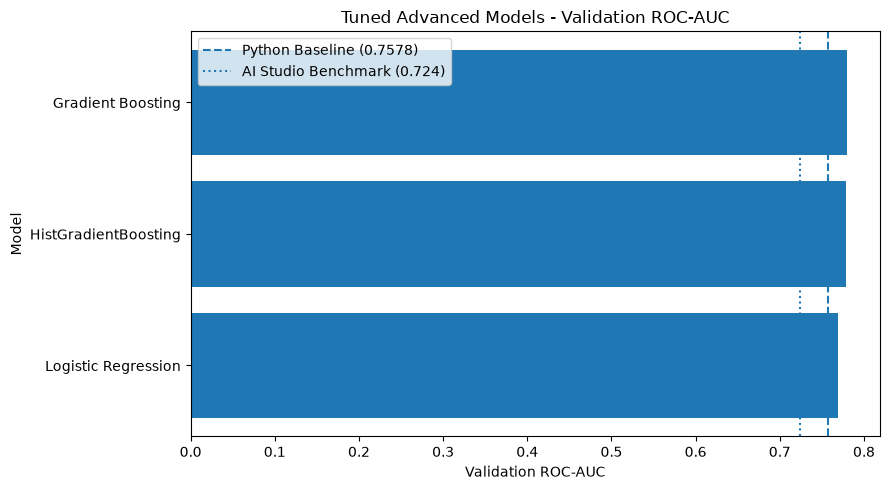

In [236]:
#ROC-AUC plot
tuned_roc_plot = tuned_validation_results.sort_values("Validation ROC-AUC", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(tuned_roc_plot["Model"], tuned_roc_plot["Validation ROC-AUC"])
plt.axvline(
    x=PYTHON_BASELINE_VALIDATION_AUC,
    linestyle="--",
    label="Python Baseline (0.7578)"
)
plt.axvline(
    x=AI_STUDIO_BENCHMARK_VALIDATION_AUC,
    linestyle=":",
    label="AI Studio Benchmark (0.724)"
)
plt.xlabel("Validation ROC-AUC")
plt.ylabel("Model")
plt.title("Tuned Advanced Models - Validation ROC-AUC")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tuned_models_validation_roc_auc.png", dpi=300, bbox_inches="tight")
plt.show()

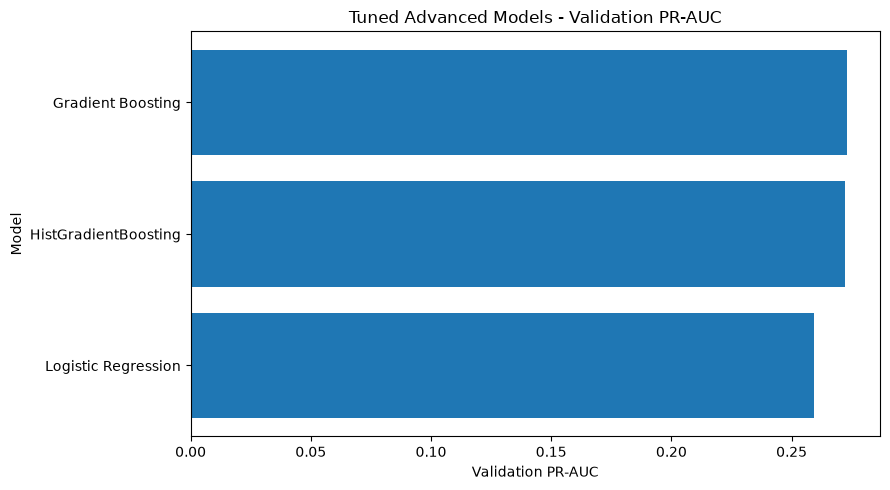

In [237]:
#PR-AUC plot
tuned_pr_plot = tuned_validation_results.sort_values("Validation PR-AUC", ascending=True)
plt.figure(figsize=(9, 5))
plt.barh(tuned_pr_plot["Model"], tuned_pr_plot["Validation PR-AUC"])
plt.xlabel("Validation PR-AUC")
plt.ylabel("Model")
plt.title("Tuned Advanced Models - Validation PR-AUC")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tuned_models_validation_pr_auc.png", dpi=300, bbox_inches="tight")
plt.show()

7.6 Tuned vs Pre-Tuning Comparison

In [238]:
pre_tuning_results = pd.DataFrame({
    "Model": [
        "HistGradientBoosting",
        "Gradient Boosting",
        "Logistic Regression"
    ],
    "Pre-Tuning ROC-AUC": [
        previous_hist_weighted["Validation ROC-AUC"],
        previous_gb_weighted["Validation ROC-AUC"],
        previous_lr_balanced["Validation ROC-AUC"]
    ],
    "Pre-Tuning PR-AUC": [
        previous_hist_weighted["Validation PR-AUC"],
        previous_gb_weighted["Validation PR-AUC"],
        previous_lr_balanced["Validation PR-AUC"]
    ],
    "Pre-Tuning Recall": [
        previous_hist_weighted["Recall"],
        previous_gb_weighted["Recall"],
        previous_lr_balanced["Recall"]
    ],
    "Pre-Tuning Precision": [
        previous_hist_weighted["Precision"],
        previous_gb_weighted["Precision"],
        previous_lr_balanced["Precision"]
    ]
})

In [239]:
tuned_compact_results = (
    tuned_validation_results[
        [
            "Model",
            "Validation ROC-AUC",
            "Validation PR-AUC",
            "Recall",
            "Precision",
            "F1"
        ]
    ].rename(
        columns={
            "Validation ROC-AUC": "Tuned ROC-AUC",
            "Validation PR-AUC": "Tuned PR-AUC",
            "Recall": "Tuned Recall",
            "Precision": "Tuned Precision",
            "F1": "Tuned F1"
        }
    )
)

In [240]:
#Mergeamos
tuning_impact_comparison = pd.merge(pre_tuning_results, tuned_compact_results, on="Model", how="inner")

#Calculamos los cambios
tuning_impact_comparison["ROC-AUC Change"] = tuning_impact_comparison["Tuned ROC-AUC"] - tuning_impact_comparison["Pre-Tuning ROC-AUC"]
tuning_impact_comparison["PR-AUC Change"] = tuning_impact_comparison["Tuned PR-AUC"] - tuning_impact_comparison["Pre-Tuning PR-AUC"]
tuning_impact_comparison["Recall Change"] = tuning_impact_comparison["Tuned Recall"] - tuning_impact_comparison["Pre-Tuning Recall"]
tuning_impact_comparison["Precision Change"] = tuning_impact_comparison["Tuned Precision"] - tuning_impact_comparison["Pre-Tuning Precision"]

In [241]:
tuning_impact_comparison.sort_values("Tuned ROC-AUC", ascending=False)

,Model,Pre-Tuning ROC-AUC,Pre-Tuning PR-AUC,Pre-Tuning Recall,Pre-Tuning Precision,Tuned ROC-AUC,Tuned PR-AUC,Tuned Recall,Tuned Precision,Tuned F1,ROC-AUC Change,PR-AUC Change,Recall Change,Precision Change
1,Gradient Boosting,0.770921,0.261807,0.693609,0.173986,0.780064,0.27311,0.698443,0.180927,0.287403,0.009142,0.011303,0.004834,0.00694
0,HistGradientBoosting,0.779601,0.274897,0.689313,0.184358,0.778618,0.272357,0.696026,0.180867,0.287123,-0.000983,-0.00254,0.006713,-0.003491
2,Logistic Regression,0.769185,0.259085,0.697637,0.172235,0.769453,0.259483,0.699248,0.172828,0.277154,0.000268,0.000398,0.001611,0.000593


7.7 Comparison Against Project Benchmarks

In [242]:
tuned_benchmark_comparison = tuned_validation_results[["Model", "Validation ROC-AUC"]].copy()

#Añadimos los benchmarks
tuned_benchmark_comparison["Python Baseline"] = PYTHON_BASELINE_VALIDATION_AUC
tuned_benchmark_comparison["AI Studio Benchmark"] = AI_STUDIO_BENCHMARK_VALIDATION_AUC

In [243]:
tuned_benchmark_comparison["Difference vs Python Baseline"] = tuned_benchmark_comparison["Validation ROC-AUC"] - PYTHON_BASELINE_VALIDATION_AUC
tuned_benchmark_comparison["Difference vs AI Studio"] = tuned_benchmark_comparison["Validation ROC-AUC"] - AI_STUDIO_BENCHMARK_VALIDATION_AUC
tuned_benchmark_comparison["Beats Python Baseline"] = tuned_benchmark_comparison["Validation ROC-AUC"] > PYTHON_BASELINE_VALIDATION_AUC

In [244]:
tuned_benchmark_comparison.sort_values("Validation ROC-AUC", ascending=False)

,Model,Validation ROC-AUC,Python Baseline,AI Studio Benchmark,Difference vs Python Baseline,Difference vs AI Studio,Beats Python Baseline
0,Gradient Boosting,0.780064,0.7578,0.724,0.022264,0.056064,True
1,HistGradientBoosting,0.778618,0.7578,0.724,0.020818,0.054618,True
2,Logistic Regression,0.769453,0.7578,0.724,0.011653,0.045453,True


7.8 Overall Advanced Model Ranking

In [245]:
overall_advanced_ranking = advanced_experiment_results.sort_values("Validation ROC-AUC", ascending=False).reset_index(drop=True).copy()
overall_advanced_ranking.insert(0, "Overall Rank", range(1, len(overall_advanced_ranking) + 1))
overall_advanced_ranking[
    [
        "Overall Rank",
        "Model",
        "Configuration",
        "Validation ROC-AUC",
        "Validation PR-AUC",
        "Precision",
        "Recall",
        "F1",
        "Improvement vs Python Baseline"
    ]
].head(10)

,Overall Rank,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Precision,Recall,F1,Improvement vs Python Baseline
0,1,Gradient Boosting,Advanced Features - Tuned Weighted,0.780064,0.27311,0.180927,0.698443,0.287403,0.022264
1,2,HistGradientBoosting,Advanced Features - Weighted,0.779601,0.274897,0.184358,0.689313,0.290911,0.021801
2,3,HistGradientBoosting,Advanced Features - Default,0.77943,0.271389,0.53629,0.035714,0.066969,0.02163
3,4,HistGradientBoosting,Advanced Features - Tuned Weighted,0.778618,0.272357,0.180867,0.696026,0.287123,0.020818
4,5,Gradient Boosting,Advanced Features - Weighted,0.770921,0.261807,0.173986,0.693609,0.278191,0.013121
5,6,Logistic Regression,Advanced Features - Tuned Balanced,0.769453,0.259483,0.172828,0.699248,0.277154,0.011653
6,7,Logistic Regression,Advanced Features - Default,0.769322,0.261664,0.584112,0.033566,0.063484,0.011522
7,8,Logistic Regression,Advanced Features - Balanced,0.769185,0.259085,0.172235,0.697637,0.276265,0.011385
8,9,Gradient Boosting,Advanced Features - Default,0.768499,0.263087,0.664384,0.026047,0.050129,0.010699
9,10,Random Forest,Advanced Features - Balanced,0.760822,0.23542,0.416561,0.087809,0.145043,0.003022


In [246]:
#Extraer mejor configuración global
best_advanced_configuration = overall_advanced_ranking.iloc[0]

print("Best advanced model:", best_advanced_configuration["Model"])
print("Best configuration:", best_advanced_configuration["Configuration"])
print("Validation ROC-AUC:", round(best_advanced_configuration["Validation ROC-AUC"], 6))
print("Validation PR-AUC:", round(best_advanced_configuration["Validation PR-AUC"], 6))
print("Improvement vs Python baseline:", round(best_advanced_configuration["Improvement vs Python Baseline"], 6))

Best advanced model: Gradient Boosting
Best configuration: Advanced Features - Tuned Weighted
Validation ROC-AUC: 0.780064
Validation PR-AUC: 0.27311
Improvement vs Python baseline: 0.022264


7.9 Export Evaluation Results

In [247]:
tuned_validation_results.to_csv(RESULTS_DIR / "tuned_validation_results.csv", index=False)
tuning_impact_comparison.to_csv(RESULTS_DIR / "tuning_impact_comparison.csv", index=False)
tuned_benchmark_comparison.to_csv(RESULTS_DIR / "tuned_benchmark_comparison.csv", index=False)
overall_advanced_ranking.to_csv(RESULTS_DIR / "overall_advanced_model_ranking.csv", index=False)

The tuned candidate models were evaluated on the fixed validation partition using the same evaluation framework applied throughout advanced modelling.

The final interpretation considers whether hyperparameter optimisation improved each model relative to its corresponding pre-tuning configuration and identifies the strongest validation configuration across all advanced modelling experiments.

In [248]:
overall_advanced_ranking[
    [
        "Overall Rank",
        "Model",
        "Configuration",
        "Validation ROC-AUC",
        "Validation PR-AUC",
        "Precision",
        "Recall",
        "F1",
        "Improvement vs Python Baseline"
    ]
].head(10)

,Overall Rank,Model,Configuration,Validation ROC-AUC,Validation PR-AUC,Precision,Recall,F1,Improvement vs Python Baseline
0,1,Gradient Boosting,Advanced Features - Tuned Weighted,0.780064,0.27311,0.180927,0.698443,0.287403,0.022264
1,2,HistGradientBoosting,Advanced Features - Weighted,0.779601,0.274897,0.184358,0.689313,0.290911,0.021801
2,3,HistGradientBoosting,Advanced Features - Default,0.77943,0.271389,0.53629,0.035714,0.066969,0.02163
3,4,HistGradientBoosting,Advanced Features - Tuned Weighted,0.778618,0.272357,0.180867,0.696026,0.287123,0.020818
4,5,Gradient Boosting,Advanced Features - Weighted,0.770921,0.261807,0.173986,0.693609,0.278191,0.013121
5,6,Logistic Regression,Advanced Features - Tuned Balanced,0.769453,0.259483,0.172828,0.699248,0.277154,0.011653
6,7,Logistic Regression,Advanced Features - Default,0.769322,0.261664,0.584112,0.033566,0.063484,0.011522
7,8,Logistic Regression,Advanced Features - Balanced,0.769185,0.259085,0.172235,0.697637,0.276265,0.011385
8,9,Gradient Boosting,Advanced Features - Default,0.768499,0.263087,0.664384,0.026047,0.050129,0.010699
9,10,Random Forest,Advanced Features - Balanced,0.760822,0.23542,0.416561,0.087809,0.145043,0.003022


7.10 Section Conclusions



The three optimised candidate models were evaluated on the same fixed validation partition after hyperparameter optimisation had been completed exclusively using the training data.

The strongest overall advanced configuration was **tuned weighted Gradient Boosting**, which achieved a validation ROC-AUC of **0.7801** and a PR-AUC of **0.2731**.

This represents an improvement of approximately **0.0223 ROC-AUC points** over the previous Python baseline of 0.7578 and approximately **0.0561 points** over the AI Studio benchmark of 0.724.

Hyperparameter optimisation produced different effects across the three candidate models.

For Gradient Boosting, tuning increased validation ROC-AUC from approximately **0.7709 to 0.7801**, producing a meaningful improvement in discriminatory performance.

For HistGradientBoosting, the tuned weighted configuration achieved approximately **0.7786**, slightly below the pre-tuning weighted result of **0.7796**. This demonstrates that hyperparameter optimisation does not necessarily improve generalisation performance and reinforces the importance of evaluating tuned configurations on an independent validation partition.

Logistic Regression remained highly competitive but showed only a small improvement after tuning, increasing from approximately **0.7692 to 0.7695** ROC-AUC.

The final validation ranking also showed that multiple advanced configurations exceeded the original Python baseline, including both boosting architectures and Logistic Regression.

The selected advanced candidate is therefore **tuned weighted Gradient Boosting**, with a validation ROC-AUC of **0.7801**.

At the default 0.50 classification threshold, the selected model achieved a Recall of approximately **0.6984**, Precision of **0.1809** and F1-score of **0.2874**. These results reflect the expected trade-off introduced by imbalance-aware learning: substantially improved minority-class detection at the cost of lower Precision.

The classification threshold has not been optimised during model development. Threshold selection remains reserved for the final Evaluation stage, where the operational trade-off between false positives and false negatives can be assessed separately from model discrimination.

The internal test partition remains untouched.

In [249]:
BEST_ADVANCED_MODEL_NAME = best_advanced_configuration["Model"]
BEST_ADVANCED_CONFIGURATION = best_advanced_configuration["Configuration"]
BEST_ADVANCED_VALIDATION_AUC = best_advanced_configuration["Validation ROC-AUC"]
BEST_ADVANCED_VALIDATION_PR_AUC = best_advanced_configuration["Validation PR-AUC"]

In [250]:
print("Best Advanced Model:", BEST_ADVANCED_MODEL_NAME)
print("Configuration:", BEST_ADVANCED_CONFIGURATION)
print("Validation ROC-AUC:", round(BEST_ADVANCED_VALIDATION_AUC, 6))
print("Validation PR-AUC:", round(BEST_ADVANCED_VALIDATION_PR_AUC, 6))

Best Advanced Model: Gradient Boosting
Configuration: Advanced Features - Tuned Weighted
Validation ROC-AUC: 0.780064
Validation PR-AUC: 0.27311


## 8. Advanced Model Comparison

This section consolidates the modelling evidence generated across the benchmark, baseline and advanced modelling stages.

No additional models are trained in this section.

Instead, the objective is to compare how predictive performance evolved as the modelling workflow progressed through:

1. AI Studio benchmarking,

2. Python baseline modelling,

3. advanced feature engineering,

4. imbalance-aware learning,

5. and hyperparameter optimisation.

The comparison focuses primarily on validation ROC-AUC, while PR-AUC and threshold-dependent metrics are used to interpret minority-class behaviour and the effects of class weighting.

This consolidated analysis provides the evidence required for final candidate-model selection.

8.2 Consolidated Model Performance

In [252]:
best_default_advanced = advanced_experiment_results[advanced_experiment_results["Configuration"] == "Advanced Features - Default"].sort_values("Validation ROC-AUC", ascending=False).iloc[0]
best_imbalance_aware = (
    advanced_experiment_results[
        advanced_experiment_results["Configuration"].str.contains("Balanced|Weighted", regex=True, na=False)
        &
        ~advanced_experiment_results["Configuration"].str.contains("Tuned", na=False)
    ].sort_values(
        "Validation ROC-AUC",
        ascending=False
    ).iloc[0]
)
model_progression_summary = pd.DataFrame({
    "Stage": [
        "AI Studio Benchmark",
        "Python Baseline",
        "Advanced Default",
        "Imbalance-Aware",
        "Hyperparameter Tuned"
    ],
    "Model": [
        AI_STUDIO_BENCHMARK_MODEL,
        PYTHON_BASELINE_MODEL,
        best_default_advanced["Model"],
        best_imbalance_aware["Model"],
        BEST_ADVANCED_MODEL_NAME
    ],
    "Configuration": [
        "AI Studio Fixed Validation",
        "Baseline Features",
        best_default_advanced["Configuration"],
        best_imbalance_aware["Configuration"],
        BEST_ADVANCED_CONFIGURATION
    ],
    "Validation ROC-AUC": [
        AI_STUDIO_BENCHMARK_VALIDATION_AUC,
        PYTHON_BASELINE_VALIDATION_AUC,
        best_default_advanced["Validation ROC-AUC"],
        best_imbalance_aware["Validation ROC-AUC"],
        BEST_ADVANCED_VALIDATION_AUC
    ]
})

model_progression_summary

,Stage,Model,Configuration,Validation ROC-AUC
0,AI Studio Benchmark,Gradient Boosted Trees,AI Studio Fixed Validation,0.724000
1,Python Baseline,Gradient Boosting,Baseline Features,0.757800
2,Advanced Default,HistGradientBoosting,Advanced Features - Default,0.779430
3,Imbalance-Aware,HistGradientBoosting,Advanced Features - Weighted,0.779601
4,Hyperparameter Tuned,Gradient Boosting,Advanced Features - Tuned Weighted,0.780064


8.3 Stage-by-Stage Performance Progression

In [253]:
#Performance respecto a etapa anterior
model_progression_summary["Change vs Previous Stage"] = model_progression_summary["Validation ROC-AUC"].diff()

#Mejora respecto a ai studio
model_progression_summary["Improvement vs AI Studio"] = model_progression_summary["Validation ROC-AUC"] - AI_STUDIO_BENCHMARK_VALIDATION_AUC

#Mejora respecto al baseline de python
model_progression_summary["Improvement vs Python Baseline"] = model_progression_summary["Validation ROC-AUC"] - PYTHON_BASELINE_VALIDATION_AUC

model_progression_summary

,Stage,Model,Configuration,Validation ROC-AUC,Change vs Previous Stage,Improvement vs AI Studio,Improvement vs Python Baseline
0,AI Studio Benchmark,Gradient Boosted Trees,AI Studio Fixed Validation,0.724000,NaN,0.000000,-0.033800
1,Python Baseline,Gradient Boosting,Baseline Features,0.757800,0.033800,0.033800,0.000000
2,Advanced Default,HistGradientBoosting,Advanced Features - Default,0.779430,0.021630,0.055430,0.021630
3,Imbalance-Aware,HistGradientBoosting,Advanced Features - Weighted,0.779601,0.000171,0.055601,0.021801
4,Hyperparameter Tuned,Gradient Boosting,Advanced Features - Tuned Weighted,0.780064,0.000463,0.056064,0.022264


The modelling workflow shows a clear progression in validation discrimination.

The AI Studio benchmark established the initial reference point at a ROC-AUC of **0.724**.

The Python baseline stage improved this to **0.7578** using Gradient Boosting.

Introducing the advanced feature representation produced a further improvement, with HistGradientBoosting achieving approximately **0.7794** without hyperparameter optimisation.

Imbalance-aware training produced only a small additional ROC-AUC improvement for the strongest HistGradientBoosting model, but substantially changed minority-class behaviour.

Finally, hyperparameter optimisation identified tuned weighted Gradient Boosting as the strongest overall configuration, achieving a validation ROC-AUC of approximately **0.7801**.

The largest performance improvements therefore came from moving beyond the original benchmark and introducing the enhanced feature representation, while later optimisation stages produced smaller incremental gains.

8.4 ROC-AUC Comparison Across Stages

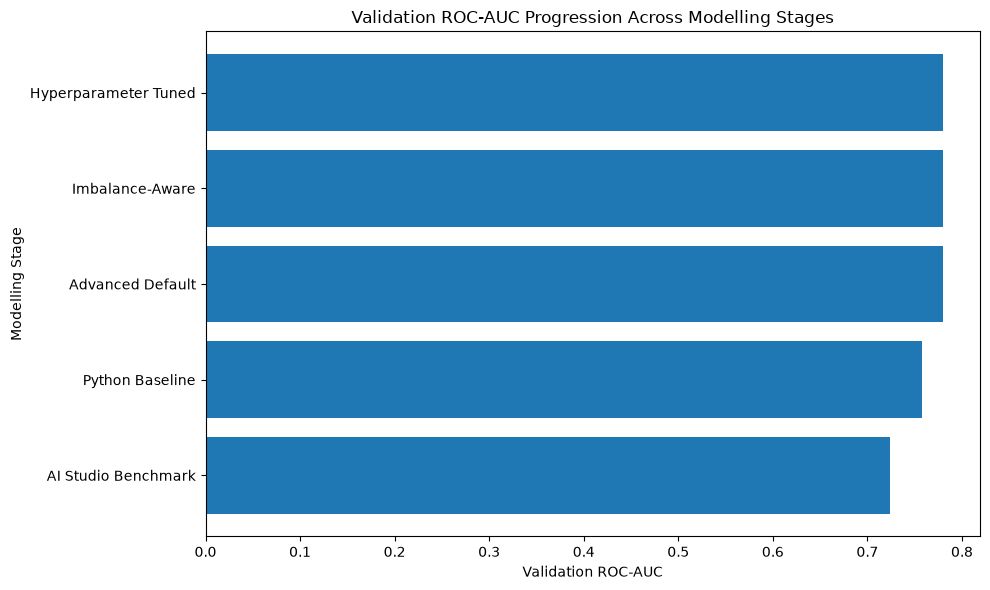

In [254]:
roc_progression_plot = model_progression_summary.sort_values("Validation ROC-AUC", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(roc_progression_plot["Stage"], roc_progression_plot["Validation ROC-AUC"])
plt.xlabel("Validation ROC-AUC")
plt.ylabel("Modelling Stage")
plt.title("Validation ROC-AUC Progression Across Modelling Stages")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "roc_auc_progression_across_stages.png", dpi=300, bbox_inches="tight")
plt.show()

8.5 PR-AUC and Minority-Class Behaviour

In [255]:
minority_class_progression = pd.DataFrame({
    "Stage": [
        "Python Baseline",
        "Advanced Default",
        "Imbalance-Aware",
        "Hyperparameter Tuned"
    ],
    "Model": [
        PYTHON_BASELINE_MODEL,
        best_default_advanced["Model"],
        best_imbalance_aware["Model"],
        BEST_ADVANCED_MODEL_NAME
    ],
    "ROC-AUC": [
        PYTHON_BASELINE_VALIDATION_AUC,
        best_default_advanced["Validation ROC-AUC"],
        best_imbalance_aware["Validation ROC-AUC"],
        BEST_ADVANCED_VALIDATION_AUC
    ],
    "PR-AUC": [
        previous_best_model["PR-AUC"],
        best_default_advanced["Validation PR-AUC"],
        best_imbalance_aware["Validation PR-AUC"],
        BEST_ADVANCED_VALIDATION_PR_AUC
    ]
})

minority_class_progression

,Stage,Model,ROC-AUC,PR-AUC
0,Python Baseline,Gradient Boosting,0.757800,0.245777
1,Advanced Default,HistGradientBoosting,0.779430,0.271389
2,Imbalance-Aware,HistGradientBoosting,0.779601,0.274897
3,Hyperparameter Tuned,Gradient Boosting,0.780064,0.273110


In [256]:
#Añadimos precision, recall, f1
minority_class_progression["Precision"] = [
    previous_best_model["Precision"],
    best_default_advanced["Precision"],
    best_imbalance_aware["Precision"],
    best_advanced_configuration["Precision"]
]
minority_class_progression["Recall"] = [
    previous_best_model["Recall"],
    best_default_advanced["Recall"],
    best_imbalance_aware["Recall"],
    best_advanced_configuration["Recall"]
]
minority_class_progression["F1"] = [
    previous_best_model["F1"],
    best_default_advanced["F1"],
    best_imbalance_aware["F1"],
    best_advanced_configuration["F1"]
]

minority_class_progression

,Stage,Model,ROC-AUC,PR-AUC,Precision,Recall,F1
0,Python Baseline,Gradient Boosting,0.757800,0.245777,0.623656,0.015575,0.030390
1,Advanced Default,HistGradientBoosting,0.779430,0.271389,0.536290,0.035714,0.066969
2,Imbalance-Aware,HistGradientBoosting,0.779601,0.274897,0.184358,0.689313,0.290911
3,Hyperparameter Tuned,Gradient Boosting,0.780064,0.273110,0.180927,0.698443,0.287403


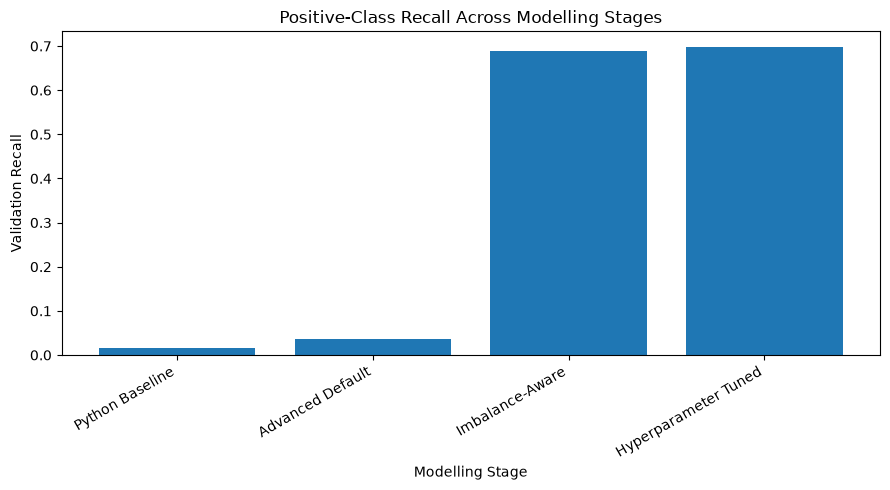

In [257]:
#Recall progression plot
plt.figure(figsize=(9, 5))
plt.bar(minority_class_progression["Stage"], minority_class_progression["Recall"])
plt.ylabel("Validation Recall")
plt.xlabel("Modelling Stage")
plt.title("Positive-Class Recall Across Modelling Stages")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "recall_progression_across_stages.png", dpi=300, bbox_inches="tight")
plt.show()

8.6 Effect of Imbalance-Aware Training

The imbalance-aware experiments showed that class weighting had a substantially larger effect on threshold-dependent classification behaviour than on ROC-AUC.

For the strongest models, weighting increased Recall from very low default-threshold values to approximately 0.69.

This improvement was accompanied by a reduction in Precision, which reflects the expected trade-off when a model is encouraged to identify a larger proportion of positive cases.

ROC-AUC changed comparatively little for the strongest boosting and logistic models.

This confirms that class weighting primarily altered the operating point of the classifiers rather than fundamentally changing their overall probability-ranking ability.

In [258]:
default_vs_weighted[
    [
        "Model",
        "Default ROC-AUC",
        "Weighted ROC-AUC",
        "ROC-AUC Change",
        "Default Recall",
        "Weighted Recall",
        "Recall Change",
        "Default Precision",
        "Weighted Precision"
    ]
].sort_values("Weighted ROC-AUC", ascending=False)

,Model,Default ROC-AUC,Weighted ROC-AUC,ROC-AUC Change,Default Recall,Weighted Recall,Recall Change,Default Precision,Weighted Precision
3,HistGradientBoosting,0.77943,0.779601,0.000171,0.035714,0.689313,0.653598,0.53629,0.184358
1,Gradient Boosting,0.768499,0.770921,0.002422,0.026047,0.693609,0.667562,0.664384,0.173986
0,Logistic Regression,0.769322,0.769185,-0.000137,0.033566,0.697637,0.664071,0.584112,0.172235
4,Random Forest,0.742441,0.760822,0.018381,0.00725,0.087809,0.080559,0.75,0.416561
2,Extra Trees,0.746266,0.752185,0.005919,0.00188,0.002954,0.001074,0.875,0.478261


8.7 Effect of Hyperparameter Tuning

Hyperparameter optimisation did not produce the same effect for every candidate model.

Gradient Boosting benefited most from tuning, increasing validation ROC-AUC from approximately **0.7709 to 0.7801**.

Logistic Regression showed only a marginal improvement, while tuned HistGradientBoosting performed slightly below its pre-tuning weighted configuration.

This result reinforces the importance of validating optimised configurations independently rather than assuming that hyperparameter tuning will necessarily improve generalisation.

In [259]:
tuning_impact_comparison[
    [
        "Model",
        "Pre-Tuning ROC-AUC",
        "Tuned ROC-AUC",
        "ROC-AUC Change",
        "Pre-Tuning PR-AUC",
        "Tuned PR-AUC",
        "PR-AUC Change"
    ]
].sort_values("Tuned ROC-AUC", ascending=False)

,Model,Pre-Tuning ROC-AUC,Tuned ROC-AUC,ROC-AUC Change,Pre-Tuning PR-AUC,Tuned PR-AUC,PR-AUC Change
1,Gradient Boosting,0.770921,0.780064,0.009142,0.261807,0.27311,0.011303
0,HistGradientBoosting,0.779601,0.778618,-0.000983,0.274897,0.272357,-0.00254
2,Logistic Regression,0.769185,0.769453,0.000268,0.259085,0.259483,0.000398


8.8 Best Configuration by Stage

In [260]:
best_configuration_by_stage = model_progression_summary[["Stage", "Model", "Configuration", "Validation ROC-AUC"]].copy()

best_configuration_by_stage

,Stage,Model,Configuration,Validation ROC-AUC
0,AI Studio Benchmark,Gradient Boosted Trees,AI Studio Fixed Validation,0.724000
1,Python Baseline,Gradient Boosting,Baseline Features,0.757800
2,Advanced Default,HistGradientBoosting,Advanced Features - Default,0.779430
3,Imbalance-Aware,HistGradientBoosting,Advanced Features - Weighted,0.779601
4,Hyperparameter Tuned,Gradient Boosting,Advanced Features - Tuned Weighted,0.780064


8.9 Final Advanced Comparison and Export Artefacts

In [261]:
final_advanced_summary = pd.DataFrame({
    "Measure": [
        "AI Studio Benchmark ROC-AUC",
        "Python Baseline ROC-AUC",
        "Best Advanced ROC-AUC",
        "Improvement vs AI Studio",
        "Improvement vs Python Baseline",
        "Best Advanced Model",
        "Best Advanced Configuration",
        "Best Advanced PR-AUC"
    ],
    "Value": [
        AI_STUDIO_BENCHMARK_VALIDATION_AUC,
        PYTHON_BASELINE_VALIDATION_AUC,
        BEST_ADVANCED_VALIDATION_AUC,
        (BEST_ADVANCED_VALIDATION_AUC - AI_STUDIO_BENCHMARK_VALIDATION_AUC),
        (BEST_ADVANCED_VALIDATION_AUC - PYTHON_BASELINE_VALIDATION_AUC),
        BEST_ADVANCED_MODEL_NAME,
        BEST_ADVANCED_CONFIGURATION,
        BEST_ADVANCED_VALIDATION_PR_AUC
    ]
})

final_advanced_summary

,Measure,Value
0,AI Studio Benchmark ROC-AUC,0.724
1,Python Baseline ROC-AUC,0.7578
2,Best Advanced ROC-AUC,0.780064
3,Improvement vs AI Studio,0.056064
4,Improvement vs Python Baseline,0.022264
5,Best Advanced Model,Gradient Boosting
6,Best Advanced Configuration,Advanced Features - Tuned Weighted
7,Best Advanced PR-AUC,0.27311


In [262]:
model_progression_summary.to_csv(RESULTS_DIR / "model_progression_summary.csv", index=False)
minority_class_progression.to_csv(RESULTS_DIR / "minority_class_progression.csv", index=False)
best_configuration_by_stage.to_csv(RESULTS_DIR / "best_configuration_by_stage.csv", index=False)
final_advanced_summary.to_csv(RESULTS_DIR / "final_advanced_summary.csv", index=False)

The consolidated comparison demonstrates a clear improvement in predictive performance across the modelling workflow.

The original AI Studio benchmark achieved a validation ROC-AUC of **0.724**.

The Python baseline improved this to **0.7578**, while the introduction of the advanced feature representation increased performance further, with default HistGradientBoosting reaching approximately **0.7794**.

Imbalance-aware training produced only a small additional ROC-AUC gain for the strongest HistGradientBoosting model, but substantially improved positive-class Recall at the default classification threshold.

Hyperparameter optimisation subsequently identified **tuned weighted Gradient Boosting** as the strongest overall advanced configuration.

The selected configuration achieved:

- Validation ROC-AUC: **0.7801**

- Validation PR-AUC: **0.2731**

- Precision: approximately **0.1809**

- Recall: approximately **0.6984**

- F1-score: approximately **0.2874**

This represents an improvement of approximately **0.0561 ROC-AUC points** over the AI Studio benchmark and approximately **0.0223 points** over the strongest Python baseline.

The modelling results also demonstrate that the largest gains were achieved through the transition from the original benchmark to Python modelling and through the enhanced feature representation. Hyperparameter optimisation produced a smaller but measurable final improvement.

The advanced modelling stage therefore identifies tuned weighted Gradient Boosting as the strongest validation candidate.

However, the model has not yet been evaluated on the internal test partition, and its classification threshold has not been optimised.

Those decisions remain reserved for the final Evaluation stage.

## 9. Comparison Againts Previous Benchmarks

The purpose of this section is to compare the strongest advanced Python model directly against the two main reference points established earlier in the project:

- the AI Studio benchmark,

- and the strongest Python baseline.

The comparison focuses on validation ROC-AUC because this metric was used consistently as the primary model-selection criterion throughout the modelling workflow.

This provides a concise assessment of whether the advanced Python modelling process achieved the original objective of improving upon the AI Studio benchmark.

In [ ]:
#Benchmarks que tenemos
final_benchmark_comparison = pd.DataFrame({
    "Stage": [
        "AI Studio Benchmark",
        "Python Baseline",
        "Advanced Python"
    ],
    "Model": [
        AI_STUDIO_BENCHMARK_MODEL,
        PYTHON_BASELINE_MODEL,
        BEST_ADVANCED_MODEL_NAME
    ],
    "Configuration": [
        "Fixed Validation Benchmark",
        "Baseline Features",
        BEST_ADVANCED_CONFIGURATION
    ],
    "Validation ROC-AUC": [
        AI_STUDIO_BENCHMARK_VALIDATION_AUC,
        PYTHON_BASELINE_VALIDATION_AUC,
        BEST_ADVANCED_VALIDATION_AUC
    ]
})

final_benchmark_comparison

,Stage,Model,Configuration,Validation ROC-AUC
0,AI Studio Benchmark,Gradient Boosted Trees,Fixed Validation Benchmark,0.724000
1,Python Baseline,Gradient Boosting,Baseline Features,0.757800
2,Advanced Python,Gradient Boosting,Advanced Features - Tuned Weighted,0.780064


In [264]:
#Absolute improvement
absolute_improvement_vs_ai = BEST_ADVANCED_VALIDATION_AUC - AI_STUDIO_BENCHMARK_VALIDATION_AUC
absolute_improvement_vs_baseline = BEST_ADVANCED_VALIDATION_AUC - PYTHON_BASELINE_VALIDATION_AUC

#Relative improvement
relative_improvement_vs_ai = (absolute_improvement_vs_ai / AI_STUDIO_BENCHMARK_VALIDATION_AUC) * 100
relative_improvement_vs_baseline = (absolute_improvement_vs_baseline / PYTHON_BASELINE_VALIDATION_AUC) * 100

benchmark_improvement_summary = pd.DataFrame({
    "Comparison": [
        "Advanced vs AI Studio",
        "Advanced vs Python Baseline"
    ],
    "Absolute ROC-AUC Improvement": [
        absolute_improvement_vs_ai,
        absolute_improvement_vs_baseline
    ],
    "Relative Improvement (%)": [
        relative_improvement_vs_ai,
        relative_improvement_vs_baseline
    ]
})

benchmark_improvement_summary

,Comparison,Absolute ROC-AUC Improvement,Relative Improvement (%)
0,Advanced vs AI Studio,0.056064,7.743628
1,Advanced vs Python Baseline,0.022264,2.937961


The strongest advanced Python model achieved a validation ROC-AUC of approximately **0.7801**.

Compared with the AI Studio benchmark ROC-AUC of **0.724**, this represents an absolute improvement of approximately **0.0561 ROC-AUC points**.

Compared with the strongest Python baseline ROC-AUC of **0.7578**, the advanced model achieved an additional improvement of approximately **0.0223 points**.

The improvement was not produced by a single modelling decision.

Instead, performance increased progressively through:

- the transition from the AI Studio benchmark to Python modelling,

- the introduction of the advanced feature representation,

- imbalance-aware learning,

- and controlled hyperparameter optimisation.

The largest improvement occurred before the final tuning stage, indicating that feature representation and model architecture contributed more to overall performance than hyperparameter optimisation alone.

The advanced model should not be interpreted as universally superior simply because it achieved a higher validation ROC-AUC.

The comparison demonstrates stronger discrimination on the fixed validation partition under the experimental protocol used in this project.

Final conclusions about generalisation must therefore remain conditional until the selected model is evaluated on the untouched internal test partition.

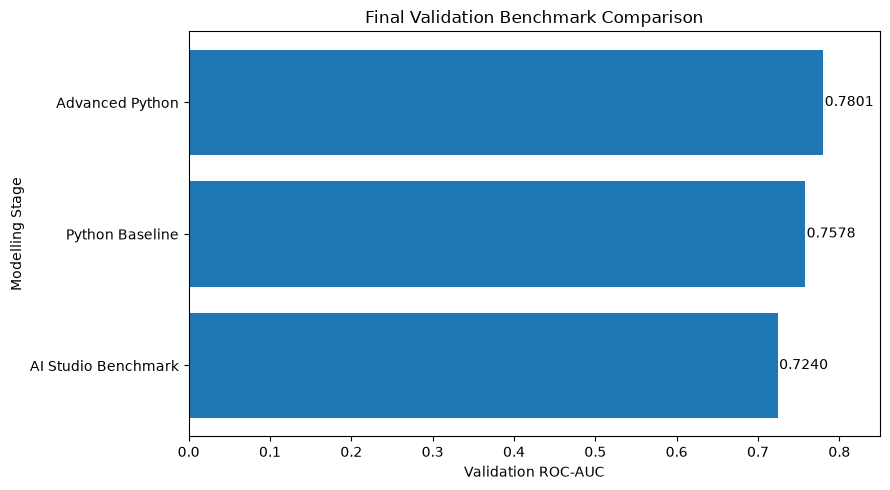

In [ ]:
#Benchmark Comparison Figure
benchmark_plot_data = final_benchmark_comparison.sort_values("Validation ROC-AUC", ascending=True)
plt.figure(figsize=(9, 5))
bars = plt.barh(benchmark_plot_data["Stage"], benchmark_plot_data["Validation ROC-AUC"])

for bar in bars:
    value = bar.get_width()
    plt.text(
        value + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center"
    )

plt.xlabel("Validation ROC-AUC")
plt.ylabel("Modelling Stage")
plt.title("Final Validation Benchmark Comparison")
plt.xlim(0, 0.85)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "final_validation_benchmark_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [267]:
#Export Benchmarks
final_benchmark_comparison.to_csv(RESULTS_DIR / "final_benchmark_comparison.csv", index=False)
benchmark_improvement_summary.to_csv(RESULTS_DIR / "benchmark_improvement_summary.csv", index=False)

The advanced Python modelling workflow successfully exceeded both previous modelling references on the fixed validation partition.

The AI Studio benchmark achieved a ROC-AUC of **0.724**, while the strongest Python baseline achieved **0.7578**.

The final advanced candidate, tuned weighted Gradient Boosting, achieved a validation ROC-AUC of approximately **0.7801**.

This represents an absolute improvement of approximately **0.0561 ROC-AUC points** over the AI Studio benchmark and approximately **0.0223 points** over the strongest Python baseline.

The results therefore demonstrate that the Python modelling workflow improved validation discrimination beyond the benchmark established in AI Studio.

However, this conclusion remains based on validation performance.

The internal test partition has not yet been used and remains reserved for final independent evaluation.

## 10. Candidate Final Model Selection

10.1 Selection Criteria

The final advanced candidate is selected according to the following criteria:

1. **Validation ROC-AUC** is the primary selection metric.

2. **PR-AUC** is considered as supporting evidence because the positive class is strongly imbalanced.

3. Precision, Recall and F1-score are reviewed to understand default-threshold behaviour.

4. Performance is compared against both the Python baseline and the AI Studio benchmark.

5. Hyperparameter optimisation must have been performed using training data only.

6. The internal test partition must not have influenced model selection.

7. The selected model must be reproducible from the saved configuration and preprocessing artefacts.

10.2 Final Candidates

In [268]:
final_candidate_row = overall_advanced_ranking.iloc[0].copy()

final_candidate_summary = pd.DataFrame({
    "Measure": [
        "Model",
        "Configuration",
        "Validation ROC-AUC",
        "Validation PR-AUC",
        "Precision",
        "Recall",
        "F1",
        "Improvement vs Python Baseline"
    ],
    "Value": [
        final_candidate_row["Model"],
        final_candidate_row["Configuration"],
        final_candidate_row["Validation ROC-AUC"],
        final_candidate_row["Validation PR-AUC"],
        final_candidate_row["Precision"],
        final_candidate_row["Recall"],
        final_candidate_row["F1"],
        final_candidate_row["Improvement vs Python Baseline"]
    ]
})

final_candidate_summary

,Measure,Value
0,Model,Gradient Boosting
1,Configuration,Advanced Features - Tuned Weighted
2,Validation ROC-AUC,0.780064
3,Validation PR-AUC,0.27311
4,Precision,0.180927
5,Recall,0.698443
6,F1,0.287403
7,Improvement vs Python Baseline,0.022264


10.3 Final Candidate Definition

In [269]:
FINAL_CANDIDATE_MODEL = tuned_gradient_boosting
FINAL_CANDIDATE_MODEL_NAME = "Gradient Boosting"
FINAL_CANDIDATE_CONFIGURATION = "Advanced Features - Tuned Weighted"
FINAL_CANDIDATE_FEATURE_SET = "Advanced Unscaled"

FINAL_CANDIDATE_BEST_PARAMS = gradient_boosting_random_search.best_params_

In [272]:
print("Final candidate:", FINAL_CANDIDATE_MODEL_NAME)
print("Configuration:", FINAL_CANDIDATE_CONFIGURATION)
print("Feature representation:", FINAL_CANDIDATE_FEATURE_SET)
print("Validation ROC-AUC:", round(BEST_ADVANCED_VALIDATION_AUC, 6))
print("Best hyperparameters:", FINAL_CANDIDATE_BEST_PARAMS)

Final candidate: Gradient Boosting
Configuration: Advanced Features - Tuned Weighted
Feature representation: Advanced Unscaled
Validation ROC-AUC: 0.780064
Best hyperparameters: {'subsample': 0.8, 'n_estimators': 250, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 3, 'learning_rate': 0.1}


10.4 Validation Performance Summary

In [273]:
final_candidate_benchmark_summary = pd.DataFrame({
    "Reference": [
        "AI Studio Benchmark",
        "Python Baseline",
        "Final Advanced Candidate"
    ],
    "Model": [
        AI_STUDIO_BENCHMARK_MODEL,
        PYTHON_BASELINE_MODEL,
        FINAL_CANDIDATE_MODEL_NAME
    ],
    "Validation ROC-AUC": [
        AI_STUDIO_BENCHMARK_VALIDATION_AUC,
        PYTHON_BASELINE_VALIDATION_AUC,
        BEST_ADVANCED_VALIDATION_AUC
    ]
})

final_candidate_benchmark_summary

,Reference,Model,Validation ROC-AUC
0,AI Studio Benchmark,Gradient Boosted Trees,0.724000
1,Python Baseline,Gradient Boosting,0.757800
2,Final Advanced Candidate,Gradient Boosting,0.780064


In [274]:
#Diferencias
FINAL_CANDIDATE_IMPROVEMENT_VS_AI = BEST_ADVANCED_VALIDATION_AUC - AI_STUDIO_BENCHMARK_VALIDATION_AUC
FINAL_CANDIDATE_IMPROVEMENT_VS_BASELINE = BEST_ADVANCED_VALIDATION_AUC - PYTHON_BASELINE_VALIDATION_AUC

print("Improvement vs AI Studio:", round(FINAL_CANDIDATE_IMPROVEMENT_VS_AI, 6))
print("Improvement vs Python baseline:", round(FINAL_CANDIDATE_IMPROVEMENT_VS_BASELINE, 6))

Improvement vs AI Studio: 0.056064
Improvement vs Python baseline: 0.022264


10.5 Selection Rationale

Tuned weighted Gradient Boosting is selected as the final advanced candidate because it achieved the highest validation ROC-AUC across all experiments conducted in the advanced modelling workflow.

The selected model achieved a validation ROC-AUC of approximately **0.7801**, exceeding:

- the AI Studio benchmark of **0.724**,

- and the strongest Python baseline of **0.7578**.

It also achieved a validation PR-AUC of approximately **0.2731**, supporting the ROC-AUC result in the context of the imbalanced target.

The imbalance-aware training configuration substantially improved minority-class detection at the default threshold, producing Recall of approximately **0.6984**.

This improvement was accompanied by lower Precision of approximately **0.1809**, demonstrating the expected trade-off between detecting more positive cases and generating additional false-positive classifications.

Gradient Boosting was selected over HistGradientBoosting because the tuned weighted Gradient Boosting configuration achieved the highest validation ROC-AUC overall.

It was also selected over Logistic Regression because the latter, although stable and competitive, achieved lower validation discrimination.

The model is therefore carried forward as the final candidate for independent test evaluation.

At this stage, the model is referred to as the **final candidate model**, rather than the final validated model.

The internal test partition has not yet been evaluated, so final conclusions about generalisation remain pending.

10.6 Save Candidate Metadata

In [276]:
final_candidate_metadata = {
    "model_name": FINAL_CANDIDATE_MODEL_NAME,
    "configuration": FINAL_CANDIDATE_CONFIGURATION,
    "feature_set": FINAL_CANDIDATE_FEATURE_SET,
    "validation_roc_auc": float(BEST_ADVANCED_VALIDATION_AUC),
    "validation_pr_auc": float(BEST_ADVANCED_VALIDATION_PR_AUC),
    "improvement_vs_ai_studio": float(FINAL_CANDIDATE_IMPROVEMENT_VS_AI),
    "improvement_vs_python_baseline": float(FINAL_CANDIDATE_IMPROVEMENT_VS_BASELINE),
    "best_hyperparameters": FINAL_CANDIDATE_BEST_PARAMS,
    "random_state": RANDOM_STATE
}

with open(RESULTS_DIR / "final_candidate_metadata.json", "w") as file:
    json.dump(final_candidate_metadata, file, indent=4)

final_candidate_summary.to_csv(RESULTS_DIR / "final_candidate_summary.csv", index=False)
final_candidate_benchmark_summary.to_csv(RESULTS_DIR / "final_candidate_benchmark_summary.csv", index=False)

final_candidate_metadata

{'model_name': 'Gradient Boosting',
 'configuration': 'Advanced Features - Tuned Weighted',
 'feature_set': 'Advanced Unscaled',
 'validation_roc_auc': 0.7800638649764181,
 'validation_pr_auc': 0.27311034489403446,
 'improvement_vs_ai_studio': 0.05606386497641813,
 'improvement_vs_python_baseline': 0.02226386497641808,
 'best_hyperparameters': {'subsample': 0.8,
  'n_estimators': 250,
  'min_samples_split': 2,
  'min_samples_leaf': 1,
  'max_depth': 3,
  'learning_rate': 0.1},
 'random_state': 1992}

The advanced modelling workflow selected **tuned weighted Gradient Boosting** as the final candidate model.

The model achieved the strongest validation ROC-AUC observed across all modelling experiments, reaching approximately **0.7801**.

This represents an improvement of approximately **0.0561 ROC-AUC points** over the AI Studio benchmark and approximately **0.0223 points** over the strongest Python baseline.

The model also achieved a validation PR-AUC of approximately **0.2731**.

At the default classification threshold, its Precision was approximately **0.1809**, Recall approximately **0.6984**, and F1-score approximately **0.2874**.

These results indicate that the selected configuration provides the strongest validation discrimination while also substantially increasing minority-class detection relative to the original unweighted models.

The selected candidate has been fixed before accessing the internal test partition.

The next stage will preserve this model configuration and associated preprocessing artefacts for final evaluation.

## 11. Save Models and Results

The purpose of this section is to persist the key artefacts produced during advanced modelling.

The selected final candidate model, supporting tuned models, performance results and modelling metadata are saved so that subsequent evaluation and deployment stages can reuse the exact fitted objects without repeating model development.

The saved artefacts also provide an auditable record of:

- the selected model,

- the selected hyperparameters,

- the feature representation,

- validation performance,

- and the experimental configuration used during model development.

11.1 Save Final Candidate Model

In [277]:
FINAL_CANDIDATE_MODEL_PATH = (MODEL_DIR / "final_candidate_gradient_boosting.joblib")

joblib.dump(FINAL_CANDIDATE_MODEL, FINAL_CANDIDATE_MODEL_PATH)

['../models/advanced/final_candidate_gradient_boosting.joblib']

In [278]:
print("Final candidate saved:", FINAL_CANDIDATE_MODEL_PATH.exists())
print("Model path:", FINAL_CANDIDATE_MODEL_PATH)

Final candidate saved: True
Model path: ../models/advanced/final_candidate_gradient_boosting.joblib


11.2 Save Tuned Candidate Models

In [279]:
tuned_model_artifacts = {
    "hist_gradient_boosting_tuned_weighted.joblib": tuned_hist_gradient_boosting,
    "gradient_boosting_tuned_weighted.joblib": tuned_gradient_boosting,
    "logistic_regression_tuned_balanced.joblib": tuned_logistic_regression
}

for filename, model in tuned_model_artifacts.items():
    joblib.dump(model, MODEL_DIR / filename)

In [280]:
for filename in tuned_model_artifacts:
    model_path = MODEL_DIR / filename
    print(filename, "->", model_path.exists())

hist_gradient_boosting_tuned_weighted.joblib -> True
gradient_boosting_tuned_weighted.joblib -> True
logistic_regression_tuned_balanced.joblib -> True


11.3 Save Final Performance Results

In [3]:
final_model_performance = pd.DataFrame({
    "Metric": [
        "Validation ROC-AUC",
        "Validation PR-AUC",
        "Validation Precision",
        "Validation Recall",
        "Validation F1",
        "Improvement vs AI Studio",
        "Improvement vs Python Baseline"
    ],
    "Value": [
        final_candidate_row["Validation ROC-AUC"],
        final_candidate_row["Validation PR-AUC"],
        final_candidate_row["Precision"],
        final_candidate_row["Recall"],
        final_candidate_row["F1"],
        FINAL_CANDIDATE_IMPROVEMENT_VS_AI,
        FINAL_CANDIDATE_IMPROVEMENT_VS_BASELINE
    ]
})

final_model_performance

NameError: name 'final_candidate_row' is not defined

In [ ]:
final_model_performance.to_csv(RESULTS_DIR / "final_model_validation_performance.csv", index=False)

11.4 Save Feature Metadata

In [ ]:
final_candidate_feature_metadata = pd.DataFrame({
    "Feature Position": range(len(advanced_unscaled_feature_names)),
    "Feature": advanced_unscaled_feature_names
})

final_candidate_feature_metadata.to_csv(RESULTS_DIR / "final_candidate_feature_names.csv", index=False)

final_candidate_feature_metadata.head()

In [ ]:
print("Saved feature count:", len(final_candidate_feature_metadata))
print("Model input feature count:", X_train_gb.shape[1])

In [ ]:
advanced_modelling_manifest = {
    "model": {
        "name":
            FINAL_CANDIDATE_MODEL_NAME,

        "configuration":
            FINAL_CANDIDATE_CONFIGURATION,

        "feature_set":
            FINAL_CANDIDATE_FEATURE_SET,

        "model_file":
            FINAL_CANDIDATE_MODEL_PATH.name
    },

    "performance": {
        "validation_roc_auc":
            float(
                final_candidate_row[
                    "Validation ROC-AUC"
                ]
            ),

        "validation_pr_auc":
            float(
                final_candidate_row[
                    "Validation PR-AUC"
                ]
            ),

        "validation_precision":
            float(
                final_candidate_row[
                    "Precision"
                ]
            ),

        "validation_recall":
            float(
                final_candidate_row[
                    "Recall"
                ]
            ),

        "validation_f1":
            float(
                final_candidate_row[
                    "F1"
                ]
            )
    },

    "benchmarks": {
        "ai_studio_roc_auc":
            float(
                AI_STUDIO_BENCHMARK_VALIDATION_AUC
            ),

        "python_baseline_roc_auc":
            float(
                PYTHON_BASELINE_VALIDATION_AUC
            )
    },

    "development": {
        "primary_metric":
            PRIMARY_METRIC,

        "development_threshold":
            MODEL_DEVELOPMENT_THRESHOLD,

        "cross_validation_folds":
            CV_FOLDS,

        "random_state":
            RANDOM_STATE,

        "test_used":
            False
    },

    "best_hyperparameters":
        FINAL_CANDIDATE_BEST_PARAMS,

    "feature_count":
        len(
            advanced_unscaled_feature_names
        )
}

with open(
    RESULTS_DIR
    / "advanced_modelling_manifest.json",
    "w"
) as file:

    json.dump(
        advanced_modelling_manifest,
        file,
        indent=4
    )

11.5 Final Artefact Verification

In [ ]:
required_model_artifacts = [
    MODEL_DIR
    / "final_candidate_gradient_boosting.joblib",

    MODEL_DIR
    / "gradient_boosting_tuned_weighted.joblib",

    MODEL_DIR
    / "hist_gradient_boosting_tuned_weighted.joblib",

    MODEL_DIR
    / "logistic_regression_tuned_balanced.joblib"
]

In [ ]:
required_result_artifacts = [
    RESULTS_DIR
    / "final_candidate_metadata.json",

    RESULTS_DIR
    / "final_candidate_summary.csv",

    RESULTS_DIR
    / "final_model_validation_performance.csv",

    RESULTS_DIR
    / "final_candidate_feature_names.csv",

    RESULTS_DIR
    / "advanced_modelling_manifest.json",

    RESULTS_DIR
    / "overall_advanced_model_ranking.csv"
]

The key artefacts produced during advanced modelling have been persisted successfully.

The selected final candidate, tuned weighted Gradient Boosting, was saved as a reusable `joblib` model together with the other tuned candidate estimators.

The saved final candidate was reloaded and verified to reproduce the original validation probabilities and ROC-AUC, confirming the integrity of the persisted model artefact.

Feature metadata, validation performance, hyperparameter settings and modelling configuration were also exported to provide an auditable record of the advanced modelling process.

The selected model remains associated with the advanced unscaled feature representation and the preprocessing artefacts created during Data Preparation.

The internal test partition remains untouched.

The advanced modelling workflow is therefore ready to transition to final evaluation.

## 12. Conclusions

The advanced modelling stage extended the previous Python baseline through three main developments:

1. an enhanced feature representation,

2. imbalance-aware model training,

3. and controlled hyperparameter optimisation.

The initial Python baseline established a validation ROC-AUC of **0.7578** using Gradient Boosting.

Using the advanced feature representation improved validation discrimination substantially. The strongest untuned advanced model, HistGradientBoosting, achieved a validation ROC-AUC of approximately **0.7794**.

Imbalance-aware training then changed minority-class behaviour substantially. Weighted HistGradientBoosting achieved approximately **0.7796 ROC-AUC** while increasing Recall to approximately **0.6893** at the default threshold.

Hyperparameter optimisation was subsequently performed on the training partition using five-fold Stratified Cross-Validation.

The strongest final advanced configuration was tuned weighted Gradient Boosting, achieving a validation ROC-AUC of approximately **0.7801** and PR-AUC of approximately **0.2731**.

The selected final candidate model is:

**Gradient Boosting — Advanced Features - Tuned Weighted**

Its fixed-validation performance was:

- ROC-AUC: **0.7801**

- PR-AUC: **0.2731**

- Precision: approximately **0.1809**

- Recall: approximately **0.6984**

- F1-score: approximately **0.2874**

This represents an improvement of approximately **0.0561 ROC-AUC points** over the AI Studio benchmark of 0.724 and approximately **0.0223 points** over the strongest Python baseline of 0.7578.

The results show that the largest modelling gains came from improved feature representation and stronger model architectures, while imbalance-aware learning primarily changed minority-class detection behaviour and hyperparameter optimisation produced a smaller final improvement.

The selected candidate and its associated metadata, feature definitions and validation results were persisted for subsequent evaluation.

Model development is now complete.

The final candidate was selected entirely using training and validation data, while the internal test partition remained untouched throughout the advanced modelling process.

The next stage will therefore evaluate the selected model on the independent test partition.

The Evaluation stage will focus on:

- final generalisation performance,

- comparison between validation and test results,

- ROC-AUC and PR-AUC,

- confusion-matrix behaviour,

- Precision and Recall trade-offs,

- classification-threshold analysis,

- and interpretation of the model from a business-risk perspective.

No further model selection or hyperparameter tuning will be performed using the test partition.